In [1]:
import pandas as pd
import numpy as np
import re
import warnings


warnings.filterwarnings("ignore")

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from scipy.sparse import hstack, csr_matrix

In [2]:
kaggle = pd.read_csv(
    "/home/iiitdwd/Documents/ExplainableAI_Project-20260327T045244Z-1-001/ExplainableAI_Project/Kaggle_urlset.csv",
    encoding="latin1",
    engine="python",
    on_bad_lines="skip"
)

In [3]:
phishstorm = pd.read_csv("/home/iiitdwd/Documents/ExplainableAI_Project-20260327T045244Z-1-001/ExplainableAI_Project/Phishtank_verified_online.csv")



In [4]:
alexa = pd.read_csv("/home/iiitdwd/Documents/ExplainableAI_Project-20260327T045244Z-1-001/ExplainableAI_Project/Alexa_top-1m.csv", header=None)

alexa.columns = ["rank","domain"]
print(alexa.head())

   rank              domain
0     1          google.com
1     2      googleapis.com
2     3       microsoft.com
3     4      www.google.com
4     5  data.microsoft.com


In [5]:
print("Kaggle :", kaggle.shape)
print("PhishTank :", phishstorm.shape)
print("Alexa :", alexa.shape)

Kaggle : (95969, 14)
PhishTank : (56406, 8)
Alexa : (1000000, 2)


In [6]:
#Convert domains to URLs and assign label 0 (legitimate).
alexa["url"] = "http://" + alexa["domain"]
alexa["label"] = 0

alexa = alexa[["url","label"]]

In [7]:
#Prepare PhishTank / PhishStorm Dataset (Phishing URLs)
phishstorm = phishstorm[["url"]]

phishstorm["label"] = 1

In [8]:
#Prepare Kaggle Dataset
kaggle = kaggle[["domain","label"]]

In [9]:
#Prepare PhishTank / PhishStorm Dataset (Phishing URLs)
phishstorm = phishstorm[["url"]]

phishstorm["label"] = 1

In [10]:
combined = pd.concat([kaggle, alexa, phishstorm], ignore_index=True)

print("Total samples:", len(combined))

Total samples: 1152375


In [11]:
combined.head()

,domain,label,url
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1.0,NaN
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1.0,NaN
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1.0,NaN
3,mail.printakid.com/www.online.americanexpress....,1.0,NaN
4,thewhiskeydregs.com/wp-content/themes/widescre...,1.0,NaN


In [12]:
combined.head()

,domain,label,url
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1.0,NaN
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1.0,NaN
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1.0,NaN
3,mail.printakid.com/www.online.americanexpress....,1.0,NaN
4,thewhiskeydregs.com/wp-content/themes/widescre...,1.0,NaN


In [13]:
print(combined.head())
print(combined.shape)
print(combined['label'].value_counts())

                                              domain  label  url
0  nobell.it/70ffb52d079109dca5664cce6f317373782/...    1.0  NaN
1  www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...    1.0  NaN
2  serviciosbys.com/paypal.cgi.bin.get-into.herf....    1.0  NaN
3  mail.printakid.com/www.online.americanexpress....    1.0  NaN
4  thewhiskeydregs.com/wp-content/themes/widescre...    1.0  NaN
(1152375, 3)
label
0.0    1048009
1.0     104308
Name: count, dtype: int64


In [14]:
print(combined.tail())
print(combined.shape)
print(combined['label'].value_counts())

        domain  label                                                url
1152370    NaN    1.0              http://webmailadmin0.myfreesites.net/
1152371    NaN    1.0  http://www.formbuddy.com/cgi-bin/formdisp.pl?u...
1152372    NaN    1.0  http://www.formbuddy.com/cgi-bin/formdisp.pl?u...
1152373    NaN    1.0       http://www.habbocreditosparati.blogspot.com/
1152374    NaN    1.0  http://creditiperhabbogratissicuro100.blogspot...
(1152375, 3)
label
0.0    1048009
1.0     104308
Name: count, dtype: int64


In [15]:
combined = combined[["url","label"]]
combined = combined.dropna()
combined = combined.drop_duplicates()

In [16]:
print(combined.head())
print(combined.shape)
print(combined['label'].value_counts())

                             url  label
95969          http://google.com    0.0
95970      http://googleapis.com    0.0
95971       http://microsoft.com    0.0
95972      http://www.google.com    0.0
95973  http://data.microsoft.com    0.0
(1056399, 2)
label
0.0    1000000
1.0      56399
Name: count, dtype: int64


In [17]:
print(combined.head())
print(combined.shape)
print(combined['label'].value_counts())

                             url  label
95969          http://google.com    0.0
95970      http://googleapis.com    0.0
95971       http://microsoft.com    0.0
95972      http://www.google.com    0.0
95973  http://data.microsoft.com    0.0
(1056399, 2)
label
0.0    1000000
1.0      56399
Name: count, dtype: int64


In [18]:
print(combined.head())

                             url  label
95969          http://google.com    0.0
95970      http://googleapis.com    0.0
95971       http://microsoft.com    0.0
95972      http://www.google.com    0.0
95973  http://data.microsoft.com    0.0


In [19]:
combined.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1056399 entries, 95969 to 1152374
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype  
---  ------  --------------    -----  
 0   url     1056399 non-null  object 
 1   label   1056399 non-null  float64
dtypes: float64(1), object(1)
memory usage: 24.2+ MB


In [20]:
#Remove Missing Values
combined.dropna(inplace=True)

In [21]:
#Remove Duplicate URLs
combined.drop_duplicates(
    subset='url',
    inplace=True
)

In [22]:
#Reset Index
combined.reset_index(
    drop=True,
    inplace=True
)

In [23]:
#Check Class Distribution
print(combined['label'].value_counts())

label
0.0    1000000
1.0      56398
Name: count, dtype: int64


In [24]:
#Shuffle Dataset
combined = combined.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [25]:
#Random Undersampling
# Separate majority and minority classes
legitimate = combined[combined['label'] == 0]

phishing = combined[combined['label'] == 1]

# Random undersampling
legitimate_sample = legitimate.sample(
    n=len(phishing),
    random_state=42
)

# Create balanced dataset
balanced = pd.concat(
    [
        legitimate_sample,
        phishing
    ]
)

# Shuffle
balanced = balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [26]:
#Verify Balance
print(balanced['label'].value_counts())

label
0.0    56398
1.0    56398
Name: count, dtype: int64


In [27]:
#Create Working DataFrame
df = balanced.copy()

In [28]:
#Lowercase URLs
df['url'] = df['url'].str.lower()

In [29]:
#Clean URLs
def clean_url(url):
    url = re.sub(r'https?://', '', url)
    url = re.sub(r'www\.', '', url)
    return url

df['clean_url'] = df['url'].apply(clean_url)

In [30]:
#Verify Clean URLs
df[['url', 'clean_url']].head()

,url,clean_url
0,http://vs-errors.eightfold.ai,vs-errors.eightfold.ai
1,https://docs.google.com/drawings/d/1626nhfrgfs...,docs.google.com/drawings/d/1626nhfrgfsbihqtkbl...
2,http://shoucheng123.com,shoucheng123.com
3,http://breakforthebestonline.com/,breakforthebestonline.com/
4,https://helps-started.ghost.io/bridge-connect/,helps-started.ghost.io/bridge-connect/


In [31]:
#Feature Engineering
# URL Length
df['url_length'] = df['clean_url'].apply(len)

# Number of dots
df['num_dots'] = df['clean_url'].str.count(r'\.')

# Number of digits
df['num_digits'] = df['clean_url'].str.count(r'\d')

# Presence of @
df['has_at_symbol'] = df['clean_url'].str.contains('@').astype(int)

# Number of hyphens
df['num_hyphens'] = df['clean_url'].str.count(r'-')

# Number of slashes
df['num_slashes'] = df['clean_url'].str.count(r'/')

# Number of question marks
df['num_question_marks'] = df['clean_url'].str.count(r'\?')

# Number of equal signs
df['num_equal'] = df['clean_url'].str.count(r'=')

# Number of underscores
df['num_underscores'] = df['clean_url'].str.count(r'_')

# Number of ampersands
df['num_ampersands'] = df['clean_url'].str.count(r'&')

In [32]:
df.head()

,url,label,clean_url,url_length,num_dots,num_digits,has_at_symbol,num_hyphens,num_slashes,num_question_marks,num_equal,num_underscores,num_ampersands
0,http://vs-errors.eightfold.ai,0.0,vs-errors.eightfold.ai,22,2,0,0,1,0,0,0,0,0
1,https://docs.google.com/drawings/d/1626nhfrgfs...,1.0,docs.google.com/drawings/d/1626nhfrgfsbihqtkbl...,76,2,7,0,0,4,0,0,1,0
2,http://shoucheng123.com,0.0,shoucheng123.com,16,1,3,0,0,0,0,0,0,0
3,http://breakforthebestonline.com/,1.0,breakforthebestonline.com/,26,1,0,0,0,1,0,0,0,0
4,https://helps-started.ghost.io/bridge-connect/,1.0,helps-started.ghost.io/bridge-connect/,38,2,0,0,2,2,0,0,0,0


In [33]:
X_numeric = df[
    [
        "url_length",
        "num_dots",
        "num_digits",
        "has_at_symbol",
        "num_hyphens",
        "num_slashes",
        "num_question_marks",
        "num_equal",
        "num_underscores",
        "num_ampersands"
    ]
]

In [34]:
# ===============================
# Define Features and Labels
# ===============================

X_numeric = df[
    [
        "url_length",
        "num_dots",
        "num_digits",
        "has_at_symbol",
        "num_hyphens",
        "num_slashes",
        "num_question_marks",
        "num_equal",
        "num_underscores",
        "num_ampersands"
    ]
]

X_text = df["clean_url"]

y = df["label"]

In [35]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text,
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [36]:
print("Training Samples :", len(X_train_text))
print("Testing Samples :", len(X_test_text))

print("\nTraining Labels")
print(y_train.value_counts())

print("\nTesting Labels")
print(y_test.value_counts())

Training Samples : 78957
Testing Samples : 33839

Training Labels
label
1.0    39479
0.0    39478
Name: count, dtype: int64

Testing Labels
label
0.0    16920
1.0    16919
Name: count, dtype: int64


In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=2000
)

X_train_tfidf = vectorizer.fit_transform(X_train_text)

X_test_tfidf = vectorizer.transform(X_test_text)

In [38]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(78957, 2000)
(33839, 2000)


In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)

X_test_num_scaled = scaler.transform(X_test_num)

In [40]:
#Convert Numeric Features to Sparse Matrix
from scipy.sparse import csr_matrix

X_train_num_sparse = csr_matrix(X_train_num_scaled)

X_test_num_sparse = csr_matrix(X_test_num_scaled)

In [41]:
#Combine TF-IDF + Handcrafted Features
from scipy.sparse import hstack

X_train = hstack(
    [
        X_train_tfidf,
        X_train_num_sparse
    ]
)

X_test = hstack(
    [
        X_test_tfidf,
        X_test_num_sparse
    ]
)

In [42]:
print(X_train.shape)

print(X_test.shape)

(78957, 2010)
(33839, 2010)


In [43]:
print(X_numeric.columns)

Index(['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens',
       'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores',
       'num_ampersands'],
      dtype='object')


In [44]:
print(df.columns.tolist())

['url', 'label', 'clean_url', 'url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [45]:
#Mutual Information Feature Selection
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

mi_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=500
)

X_train = mi_selector.fit_transform(
    X_train,
    y_train
)

X_test = mi_selector.transform(
    X_test
)

In [46]:
print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

print("Training Labels")
print(y_train.value_counts())

print("\nTesting Labels")
print(y_test.value_counts())

Training Shape : (78957, 500)
Testing Shape : (33839, 500)
Training Labels
label
1.0    39479
0.0    39478
Name: count, dtype: int64

Testing Labels
label
0.0    16920
1.0    16919
Name: count, dtype: int64


In [47]:
tfidf_feature_names = vectorizer.get_feature_names_out()

In [48]:
handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

In [49]:
all_feature_names = list(tfidf_feature_names) + handcrafted_features

In [50]:
print(len(all_feature_names))

2010


In [51]:
mi_scores = mi_selector.scores_

In [52]:
import pandas as pd

mi_df = pd.DataFrame({
    "Feature": all_feature_names,
    "MI Score": mi_scores
})

In [53]:
mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
).reset_index(drop=True)

In [54]:
print(mi_df.head(50))

               Feature  MI Score
0          num_slashes  0.617354
1                  com  0.326951
2           url_length  0.144223
3           num_digits  0.074335
4   num_question_marks  0.066889
5            num_equal  0.065206
6               google  0.053128
7                  net  0.051772
8       num_ampersands  0.050444
9                  pub  0.046513
10                docs  0.042937
11     num_underscores  0.038052
12               start  0.034810
13        presentation  0.034086
14                  de  0.032367
15                loop  0.032172
16             delayms  0.032148
17               2pacx  0.031051
18                3000  0.030835
19                 amp  0.030672
20            num_dots  0.030641
21               false  0.030452
22                 app  0.029266
23                qrco  0.028556
24                  me  0.024313
25              weebly  0.022823
26                  to  0.021511
27                 ead  0.020665
28                html  0.019794
29        

In [55]:
mi_df.to_csv("Mutual_Information_Scores.csv", index=False)

In [56]:
selected_mask = mi_selector.get_support()

selected_features = pd.DataFrame({
    "Feature": np.array(all_feature_names)[selected_mask],
    "MI Score": mi_scores[selected_mask]
}).sort_values(
    by="MI Score",
    ascending=False
).reset_index(drop=True)

selected_features.head(50)

,Feature,MI Score
0,num_slashes,0.617354
1,com,0.326951
2,url_length,0.144223
3,num_digits,0.074335
4,num_question_marks,0.066889
5,num_equal,0.065206
6,google,0.053128
7,net,0.051772
8,num_ampersands,0.050444
9,pub,0.046513


In [57]:
selected_features.to_csv("Top500_MI_Features.csv", index=False)

In [58]:
!pip install xgboost

  Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl (131.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 24.0 MB/s  0:00:13 28.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]


In [59]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt = DecisionTreeClassifier(random_state=42)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
mlp.fit(X_train, y_train)
xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [60]:
from sklearn.ensemble import VotingClassifier

# Soft Voting
sv1 = VotingClassifier(
    estimators=[('mlp', mlp), ('dt', dt)],
    voting='soft'
)

sv2 = VotingClassifier(
    estimators=[('dt', dt), ('rf', rf)],
    voting='soft'
)

sv3 = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf)],
    voting='soft'
)

# Hard Voting
hv1 = VotingClassifier(
    estimators=[('mlp', mlp), ('dt', dt)],
    voting='hard'
)

hv2 = VotingClassifier(
    estimators=[('dt', dt), ('rf', rf)],
    voting='hard'
)

hv3 = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf)],
    voting='hard'
)

sv1.fit(X_train, y_train)
sv2.fit(X_train, y_train)
sv3.fit(X_train, y_train)

hv1.fit(X_train, y_train)
hv2.fit(X_train, y_train)
hv3.fit(X_train, y_train)

,estimators,"[('xgb', ...), ('rf', ...)]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

all_models = {
    "DT": dt,
    "RF": rf,
    "MLP": mlp,
    "XGB": xgb,
    "SV1": sv1,
    "SV2": sv2,
    "SV3": sv3,
    "HV1": hv1,
    "HV2": hv2,
    "HV3": hv3
}

results = []

for name, model in all_models.items():

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results.append([
        name,
        round(accuracy_score(y_train, y_train_pred),4),
        round(accuracy_score(y_test, y_test_pred),4),
        round(precision_score(y_test, y_test_pred),4),
        round(recall_score(y_test, y_test_pred),4),
        round(f1_score(y_test, y_test_pred),4)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train_Accuracy",
        "Test_Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
)

print(results_df.sort_values(
    by="Test_Accuracy",
    ascending=False
))

  Model  Train_Accuracy  Test_Accuracy  Precision  Recall      F1
2   MLP          0.9957         0.9939     0.9992  0.9885  0.9938
1    RF          0.9973         0.9936     0.9991  0.9881  0.9936
7   HV1          0.9959         0.9936     0.9998  0.9874  0.9935
8   HV2          0.9973         0.9934     0.9992  0.9876  0.9934
6   SV3          0.9956         0.9933     0.9995  0.9871  0.9932
3   XGB          0.9946         0.9932     0.9993  0.9870  0.9931
9   HV3          0.9950         0.9931     0.9996  0.9865  0.9930
0    DT          0.9973         0.9926     0.9964  0.9887  0.9925
5   SV2          0.9973         0.9926     0.9965  0.9888  0.9926
4   SV1          0.9973         0.9926     0.9964  0.9887  0.9926


In [62]:
X_train_text_70, X_test_text_70, X_train_num_70, X_test_num_70, y_train_70, y_test_70 = train_test_split(
    X_text,
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [63]:
vectorizer_70 = TfidfVectorizer(max_features=2000)

X_train_tfidf_70 = vectorizer_70.fit_transform(X_train_text_70)

X_test_tfidf_70 = vectorizer_70.transform(X_test_text_70)

In [64]:
scaler_70 = StandardScaler()

X_train_num_scaled_70 = scaler_70.fit_transform(X_train_num_70)

X_test_num_scaled_70 = scaler_70.transform(X_test_num_70)

In [65]:
from scipy.sparse import csr_matrix

X_train_num_sparse_70 = csr_matrix(X_train_num_scaled_70)

X_test_num_sparse_70 = csr_matrix(X_test_num_scaled_70)

In [66]:
from scipy.sparse import hstack

X_train_70 = hstack([
    X_train_tfidf_70,
    X_train_num_sparse_70
])

X_test_70 = hstack([
    X_test_tfidf_70,
    X_test_num_sparse_70
])

In [67]:
print(X_train_70.shape)
print(X_test_70.shape)

(78957, 2010)
(33839, 2010)


In [68]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

mi_selector_70 = SelectKBest(
    score_func=mutual_info_classif,
    k=500
)

X_train_70 = mi_selector_70.fit_transform(
    X_train_70,
    y_train_70
)

X_test_70 = mi_selector_70.transform(
    X_test_70
)

In [69]:
print(X_train_70.shape)
print(X_test_70.shape)

print(y_train_70.value_counts())
print(y_test_70.value_counts())

(78957, 500)
(33839, 500)
label
1.0    39479
0.0    39478
Name: count, dtype: int64
label
0.0    16920
1.0    16919
Name: count, dtype: int64


In [70]:
tfidf_feature_names_70 = vectorizer_70.get_feature_names_out()

mi_scores_70 = mi_selector_70.scores_

In [71]:
X_train_70
X_test_70

y_train_70
y_test_70

100260    1.0
75016     0.0
110171    1.0
111020    1.0
92575     1.0
         ... 
8956      1.0
93549     1.0
109927    0.0
61656     1.0
38320     1.0
Name: label, Length: 33839, dtype: float64

In [76]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from xgboost import XGBClassifier

In [73]:
ensemble_models = [
    "SV1",
    "SV2",
    "SV3",
    "HV1",
    "HV2",
    "HV3"
]

In [77]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

def create_model(model_name):

    # Base models
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    dt = DecisionTreeClassifier(
        random_state=42
    )

    svm = SVC(
        probability=True,
        random_state=42
    )

    xgb = XGBClassifier(
        eval_metric='logloss',
        random_state=42
    )

    # Soft Voting Ensembles
    if model_name == "SV1":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('xgb', xgb)
            ],
            voting='soft'
        )

    elif model_name == "SV2":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm)
            ],
            voting='soft'
        )

    elif model_name == "SV3":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('dt', dt),
                ('xgb', xgb)
            ],
            voting='soft'
        )

    # Hard Voting Ensembles
    elif model_name == "HV1":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('xgb', xgb)
            ],
            voting='hard'
        )

    elif model_name == "HV2":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm)
            ],
            voting='hard'
        )

    elif model_name == "HV3":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('dt', dt),
                ('xgb', xgb)
            ],
            voting='hard'
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

In [159]:
results = []

for model_name in ensemble_models:

    print("Running:", model_name)

    train_times = []

    # Training Time (5 runs)

    for _ in range(5):

        model = create_model(model_name)

        start = time.time()

        model.fit(X_train, y_train)

        end = time.time()

        train_times.append(end - start)

    train_mean = np.mean(train_times)
    train_std = np.std(train_times)

    # Final Model

    model = create_model(model_name)

    model.fit(X_train, y_train)

    # Predictions

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    train_mcc = matthews_corrcoef(y_train, train_pred)
    test_mcc = matthews_corrcoef(y_test, test_pred)

    # Inference Time (20 runs)

    infer_times = []

    for _ in range(20):

        start = time.time()

        model.predict(X_test)

        end = time.time()

        infer_times.append(end - start)

    infer_mean = np.mean(infer_times)
    infer_std = np.std(infer_times)

    results.append([
        model_name,

        round(train_acc*100,2),
        round(test_acc*100,2),

        round(train_f1,4),
        round(test_f1,4),

        round(train_mcc,4),
        round(test_mcc,4),

        round(train_mean,4),
        round(train_std,4),

        round(infer_mean,4),
        round(infer_std,4)
    ])

Running: SV1
Running: SV2
Running: SV3
Running: HV1
Running: HV2
Running: HV3


In [160]:
P_table = pd.DataFrame(
    results,
    columns=[
        "Model",

        "Train_Accuracy(%)",
        "Test_Accuracy(%)",

        "Train_F1",
        "Test_F1",

        "Train_MCC",
        "Test_MCC",

        "Train_Time_Mean(s)",
        "Train_Time_Std(s)",

        "Inference_Mean(s)",
        "Inference_Std(s)"
    ]
)

P_table

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Std(s)
0,SV1,99.56,99.33,0.9955,0.9932,0.9911,0.9867,23.7073,0.2768,0.4736,0.0083
1,SV2,99.43,99.26,0.9943,0.9926,0.9886,0.9854,166.9357,1.0021,4.7587,0.0044
2,SV3,99.73,99.37,0.9973,0.9937,0.9946,0.9875,24.4744,0.0368,0.4778,0.0091
3,HV1,99.50,99.31,0.9949,0.9930,0.9900,0.9862,24.7014,2.6359,0.5636,0.0061
4,HV2,99.29,99.16,0.9928,0.9915,0.9859,0.9833,167.6058,0.7322,4.8818,0.0141
5,HV3,99.73,99.36,0.9973,0.9936,0.9946,0.9874,35.1480,9.4617,0.5829,0.0064


In [161]:
P_table.to_csv(
    "Voting_Models_70_30_Table.csv",
    index=False
)

P_table

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Std(s)
0,SV1,99.56,99.33,0.9955,0.9932,0.9911,0.9867,23.7073,0.2768,0.4736,0.0083
1,SV2,99.43,99.26,0.9943,0.9926,0.9886,0.9854,166.9357,1.0021,4.7587,0.0044
2,SV3,99.73,99.37,0.9973,0.9937,0.9946,0.9875,24.4744,0.0368,0.4778,0.0091
3,HV1,99.50,99.31,0.9949,0.9930,0.9900,0.9862,24.7014,2.6359,0.5636,0.0061
4,HV2,99.29,99.16,0.9928,0.9915,0.9859,0.9833,167.6058,0.7322,4.8818,0.0141
5,HV3,99.73,99.36,0.9973,0.9936,0.9946,0.9874,35.1480,9.4617,0.5829,0.0064


In [162]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt = DecisionTreeClassifier(random_state=42)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [163]:
from sklearn.ensemble import VotingClassifier

In [164]:
sv1_3 = VotingClassifier(
    estimators=[
        ('mlp', mlp),
        ('dt', dt),
        ('rf', rf)
    ],
    voting='soft'
)

In [165]:
sv2_3 = VotingClassifier(
    estimators=[
        ('dt', dt),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='soft'
)

In [166]:
sv3_3 = VotingClassifier(
    estimators=[
        ('xgb', xgb),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='soft'
)

In [167]:
hv1_3 = VotingClassifier(
    estimators=[
        ('mlp', mlp),
        ('dt', dt),
        ('rf', rf)
    ],
    voting='hard'
)

In [168]:
hv2_3 = VotingClassifier(
    estimators=[
        ('dt', dt),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='hard'
)

In [169]:
hv3_3 = VotingClassifier(
    estimators=[
        ('xgb', xgb),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='hard'
)

In [170]:
sv1_3.fit(X_train, y_train)
sv2_3.fit(X_train, y_train)
sv3_3.fit(X_train, y_train)

hv1_3.fit(X_train, y_train)
hv2_3.fit(X_train, y_train)
hv3_3.fit(X_train, y_train)

,estimators,"[('xgb', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None


In [171]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

In [172]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

models_3 = {
    "SV1_3": sv1_3,
    "SV2_3": sv2_3,
    "SV3_3": sv3_3,
    "HV1_3": hv1_3,
    "HV2_3": hv2_3,
    "HV3_3": hv3_3
}

results_3 = []

for name, model in models_3.items():

    print("Running:", name)

    # ----------------------------
    # Training Time (5 Runs)
    # ----------------------------
    train_times = []

    for _ in range(5):

        start = time.time()

        model.fit(X_train, y_train)

        end = time.time()

        train_times.append(end - start)

    train_mean = np.mean(train_times)
    train_std = np.std(train_times)

    # ----------------------------
    # Final Training
    # ----------------------------
    model.fit(X_train, y_train)

    # ----------------------------
    # Predictions
    # ----------------------------
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    train_mcc = matthews_corrcoef(y_train, train_pred)
    test_mcc = matthews_corrcoef(y_test, test_pred)

    # ----------------------------
    # Inference Time (20 Runs)
    # ----------------------------
    infer_times = []

    for _ in range(20):

        start = time.time()

        model.predict(X_test)

        end = time.time()

        infer_times.append(end - start)

    infer_mean = np.mean(infer_times)
    infer_std = np.std(infer_times)

    # ----------------------------
    # Store Results
    # ----------------------------
    results_3.append([
        name,

        round(train_acc * 100, 2),
        round(test_acc * 100, 2),

        round(train_f1, 4),
        round(test_f1, 4),

        round(train_mcc, 4),
        round(test_mcc, 4),

        round(train_mean, 4),
        round(train_std, 4),

        round(infer_mean, 4),
        round(infer_std, 4)
    ])

# -----------------------------------
# Final DataFrame
# -----------------------------------

results_3_df = pd.DataFrame(
    results_3,
    columns=[
        "Model",
        "Train_Accuracy(%)",
        "Test_Accuracy(%)",
        "Train_F1",
        "Test_F1",
        "Train_MCC",
        "Test_MCC",
        "Train_Time_Mean(s)",
        "Train_Time_Std(s)",
        "Inference_Mean(s)",
        "Inference_Time_Std(s)"
    ]
)

results_3_df

Running: SV1_3
Running: SV2_3
Running: SV3_3
Running: HV1_3
Running: HV2_3
Running: HV3_3


,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Time_Std(s)
0,SV1_3,99.73,99.37,0.9973,0.9937,0.9947,0.9875,64.8787,1.0766,0.2039,0.0045
1,SV2_3,99.73,99.37,0.9973,0.9937,0.9947,0.9875,65.1220,1.0267,0.2030,0.0075
2,SV3_3,99.58,99.37,0.9958,0.9937,0.9917,0.9875,119.5626,25.7310,0.2218,0.0056
3,HV1_3,99.73,99.38,0.9973,0.9938,0.9946,0.9876,111.2741,12.3640,0.3214,0.0122
4,HV2_3,99.73,99.38,0.9973,0.9938,0.9946,0.9876,125.6267,5.6417,0.2687,0.0283
5,HV3_3,99.59,99.38,0.9959,0.9938,0.9918,0.9877,121.3918,10.2749,0.2783,0.0106


In [173]:
import pandas as pd

# Copy DataFrames
df2 = P_table.copy()
df3 = results_3_df.copy()

# Remove suffix from model names
df3["Model"] = df3["Model"].str.replace("_3", "", regex=False)

# Merge both tables
comparison_table = pd.merge(
    df2,
    df3,
    on="Model",
    suffixes=("_2BLs", "_3BLs")
)

# Keep only required columns
comparison_table = comparison_table[
    [
        "Model",

        "Train_Accuracy(%)_2BLs",
        "Train_Accuracy(%)_3BLs",

        "Test_Accuracy(%)_2BLs",
        "Test_Accuracy(%)_3BLs",

        "Train_Time_Mean(s)_2BLs",
        "Train_Time_Mean(s)_3BLs",

        "Inference_Mean(s)_2BLs",
        "Inference_Mean(s)_3BLs"
    ]
]

# Rename columns exactly like the paper
comparison_table.columns = [
    "Model",

    "Train Accuracy (%)\n2BLs",
    "Train Accuracy (%)\n3BLs",

    "Test Accuracy (%)\n2BLs",
    "Test Accuracy (%)\n3BLs",

    "Train Time (s)\n2BLs",
    "Train Time (s)\n3BLs",

    "Inference Time (s)\n2BLs",
    "Inference Time (s)\n3BLs"
]

comparison_table

,Model,Train Accuracy (%)\n2BLs,Train Accuracy (%)\n3BLs,Test Accuracy (%)\n2BLs,Test Accuracy (%)\n3BLs,Train Time (s)\n2BLs,Train Time (s)\n3BLs,Inference Time (s)\n2BLs,Inference Time (s)\n3BLs
0,SV1,99.56,99.73,99.33,99.37,23.7073,64.8787,0.4736,0.2039
1,SV2,99.43,99.73,99.26,99.37,166.9357,65.1220,4.7587,0.2030
2,SV3,99.73,99.58,99.37,99.37,24.4744,119.5626,0.4778,0.2218
3,HV1,99.50,99.73,99.31,99.38,24.7014,111.2741,0.5636,0.3214
4,HV2,99.29,99.73,99.16,99.38,167.6058,125.6267,4.8818,0.2687
5,HV3,99.73,99.59,99.36,99.38,35.1480,121.3918,0.5829,0.2783


In [174]:
# Save comparison table as CSV
comparison_table.to_csv(
    "Comparison_2BLs_vs_3BLs.csv",
    index=False
)

print("CSV saved successfully.")

CSV saved successfully.


In [175]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature_Index": range(X_train.shape[1]),
    "MI_Score": mi_scores
})

mi_df = mi_df.sort_values(
    by="MI_Score",
    ascending=False
)

mi_df.head(20)

,Feature_Index,MI_Score
495,495,0.617354
108,108,0.326951
490,490,0.144223
492,492,0.074335
496,496,0.066889
497,497,0.065206
200,200,0.053128
291,291,0.051772
499,499,0.050444
340,340,0.046513


In [176]:
print("Total Features :", len(mi_scores))

print(
    "Features with MI > 0 :",
    (mi_df["MI_Score"] > 0).sum())

Total Features : 500
Features with MI > 0 : 500


In [177]:
top200_idx = mi_df.head(200)["Feature_Index"].values

In [178]:
print("Top200:", len(top200_idx))

Top200: 200


In [179]:
X_train_200 = X_train[:, top200_idx]
X_test_200 = X_test[:, top200_idx]

In [180]:
print("200 Features:", X_train_200.shape)

200 Features: (78957, 200)


In [181]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt_200 = DecisionTreeClassifier(random_state=42)

rf_200 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp_200 = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb_200 = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

dt_200.fit(X_train_200, y_train)
rf_200.fit(X_train_200, y_train)
mlp_200.fit(X_train_200, y_train)
xgb_200.fit(X_train_200, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [182]:
from sklearn.ensemble import VotingClassifier

In [183]:
sv1_200 = VotingClassifier(
    estimators=[
        ('mlp', mlp_200),
        ('dt', dt_200),
        ('rf', rf_200)
    ],
    voting='soft'
)

In [184]:
sv2_200 = VotingClassifier(
    estimators=[
        ('dt', dt_200),
        ('rf', rf_200),
        ('mlp', mlp_200)
    ],
    voting='soft'
)

In [185]:
sv3_200 = VotingClassifier(
    estimators=[
        ('xgb', xgb_200),
        ('rf', rf_200),
        ('mlp', mlp_200)
    ],
    voting='soft'
)

In [186]:
hv1_200 = VotingClassifier(
    estimators=[
        ('mlp', mlp_200),
        ('dt', dt_200),
        ('rf', rf_200)
    ],
    voting='hard'
)

In [187]:
hv2_200 = VotingClassifier(
    estimators=[
        ('dt', dt_200),
        ('rf', rf_200),
        ('mlp', mlp_200)
    ],
    voting='hard'
)

In [188]:
hv3_200 = VotingClassifier(
    estimators=[
        ('xgb', xgb_200),
        ('rf', rf_200),
        ('mlp', mlp_200)
    ],
    voting='hard'
)

In [189]:
sv1_200.fit(X_train_200, y_train)
sv2_200.fit(X_train_200, y_train)
sv3_200.fit(X_train_200, y_train)

hv1_200.fit(X_train_200, y_train)
hv2_200.fit(X_train_200, y_train)
hv3_200.fit(X_train_200, y_train)

,estimators,"[('xgb', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None


In [190]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

models_200 = {
    "SV1": sv1_200,
    "SV2": sv2_200,
    "SV3": sv3_200,
    "HV1": hv1_200,
    "HV2": hv2_200,
    "HV3": hv3_200
}

results_200 = []

for name, model in models_200.items():

    train_pred = model.predict(X_train_200)
    test_pred = model.predict(X_test_200)

    results_200.append([
        name,
        round(accuracy_score(y_train, train_pred)*100,2),
        round(accuracy_score(y_test, test_pred)*100,2),
        round(f1_score(y_train, train_pred),4),
        round(f1_score(y_test, test_pred),4),
        round(matthews_corrcoef(y_train, train_pred),4),
        round(matthews_corrcoef(y_test, test_pred),4)
    ])

results_200_df = pd.DataFrame(
    results_200,
    columns=[
        "Model",
        "Train_Accuracy(%)",
        "Test_Accuracy(%)",
        "Train_F1",
        "Test_F1",
        "Train_MCC",
        "Test_MCC"
    ]
)

results_200_df.sort_values(
    by="Test_Accuracy(%)",
    ascending=False
)

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC
2,SV3,99.51,99.34,0.9951,0.9933,0.9902,0.9868
5,HV3,99.50,99.32,0.9950,0.9932,0.9901,0.9865
3,HV1,99.72,99.31,0.9972,0.9930,0.9944,0.9862
4,HV2,99.72,99.31,0.9972,0.9930,0.9944,0.9862
1,SV2,99.72,99.28,0.9972,0.9928,0.9944,0.9857
0,SV1,99.72,99.28,0.9972,0.9928,0.9944,0.9857


In [191]:
top100_idx = mi_df.head(100)["Feature_Index"].values

In [192]:
print("Top100:", len(top100_idx))

Top100: 100


In [193]:
X_train_100 = X_train[:, top100_idx]
X_test_100 = X_test[:, top100_idx]

In [194]:
print("100 Features:", X_train_100.shape)

100 Features: (78957, 100)


In [195]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt_100 = DecisionTreeClassifier(random_state=42)

rf_100 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp_100 = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb_100 = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

dt_100.fit(X_train_100, y_train)
rf_100.fit(X_train_100, y_train)
mlp_100.fit(X_train_100, y_train)
xgb_100.fit(X_train_100, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [196]:
from sklearn.ensemble import VotingClassifier

In [197]:
sv1_100 = VotingClassifier(
    estimators=[
        ('mlp', mlp_100),
        ('dt', dt_100),
        ('rf', rf_100)
    ],
    voting='soft'
)

In [198]:
sv2_100 = VotingClassifier(
    estimators=[
        ('dt', dt_100),
        ('rf', rf_100),
        ('mlp', mlp_100)
    ],
    voting='soft'
)

In [199]:
sv3_100 = VotingClassifier(
    estimators=[
        ('xgb', xgb_100),
        ('rf', rf_100),
        ('mlp', mlp_100)
    ],
    voting='soft'
)

In [200]:
hv1_100 = VotingClassifier(
    estimators=[
        ('mlp', mlp_100),
        ('dt', dt_100),
        ('rf', rf_100)
    ],
    voting='hard'
)

In [201]:
hv1_100 = VotingClassifier(
    estimators=[
        ('mlp', mlp_100),
        ('dt', dt_100),
        ('rf', rf_100)
    ],
    voting='hard'
)

In [202]:
hv2_100 = VotingClassifier(
    estimators=[
        ('dt', dt_100),
        ('rf', rf_100),
        ('mlp', mlp_100)
    ],
    voting='hard'
)

In [203]:
hv3_100 = VotingClassifier(
    estimators=[
        ('xgb', xgb_100),
        ('rf', rf_100),
        ('mlp', mlp_100)
    ],
    voting='hard'
)

In [204]:
sv1_100.fit(X_train_100, y_train)
sv2_100.fit(X_train_100, y_train)
sv3_100.fit(X_train_100, y_train)

hv1_100.fit(X_train_100, y_train)
hv2_100.fit(X_train_100, y_train)
hv3_100.fit(X_train_100, y_train)

,estimators,"[('xgb', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None


In [205]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

# Store all 100-feature ensemble models
models_100 = {
    "SV1": sv1_100,
    "SV2": sv2_100,
    "SV3": sv3_100,
    "HV1": hv1_100,
    "HV2": hv2_100,
    "HV3": hv3_100
}

# Store results
results_100 = []

for name, model in models_100.items():

    # Predictions using 100 selected features
    train_pred = model.predict(X_train_100)
    test_pred = model.predict(X_test_100)

    # Calculate metrics
    results_100.append([
        name,
        round(accuracy_score(y_train, train_pred) * 100, 2),
        round(accuracy_score(y_test, test_pred) * 100, 2),
        round(f1_score(y_train, train_pred), 4),
        round(f1_score(y_test, test_pred), 4),
        round(matthews_corrcoef(y_train, train_pred), 4),
        round(matthews_corrcoef(y_test, test_pred), 4)
    ])

# Create DataFrame
results_100_df = pd.DataFrame(
    results_100,
    columns=[
        "Model",
        "Train_Accuracy(%)",
        "Test_Accuracy(%)",
        "Train_F1",
        "Test_F1",
        "Train_MCC",
        "Test_MCC"
    ]
)

# Display results sorted by test accuracy
results_100_df.sort_values(
    by="Test_Accuracy(%)",
    ascending=False
)

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC
5,HV3,99.45,99.24,0.9944,0.9924,0.9890,0.9850
2,SV3,99.45,99.23,0.9945,0.9923,0.9891,0.9848
3,HV1,99.69,99.23,0.9968,0.9923,0.9937,0.9847
4,HV2,99.69,99.23,0.9968,0.9923,0.9937,0.9847
1,SV2,99.69,99.21,0.9968,0.9920,0.9937,0.9842
0,SV1,99.69,99.21,0.9968,0.9920,0.9937,0.9842


In [206]:
top50_idx = mi_df.head(50)["Feature_Index"].values

In [207]:
print("Top50:", len(top50_idx))

Top50: 50


In [208]:
X_train_50 = X_train[:, top50_idx]
X_test_50 = X_test[:, top50_idx]

In [209]:
print("50 Features:", X_train_50.shape)

50 Features: (78957, 50)


In [210]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt_50 = DecisionTreeClassifier(random_state=42)

rf_50 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp_50 = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb_50 = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

dt_50.fit(X_train_50, y_train)
rf_50.fit(X_train_50, y_train)
mlp_50.fit(X_train_50, y_train)
xgb_50.fit(X_train_50, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [211]:
from sklearn.ensemble import VotingClassifier

In [212]:
sv1_50 = VotingClassifier(
    estimators=[
        ('mlp', mlp_50),
        ('dt', dt_50),
        ('rf', rf_50)
    ],
    voting='soft'
)

In [213]:
sv2_50 = VotingClassifier(
    estimators=[
        ('dt', dt_50),
        ('rf', rf_50),
        ('mlp', mlp_50)
    ],
    voting='soft'
)

In [214]:
sv3_50 = VotingClassifier(
    estimators=[
        ('xgb', xgb_50),
        ('rf', rf_50),
        ('mlp', mlp_50)
    ],
    voting='soft'
)

In [215]:
hv1_50 = VotingClassifier(
    estimators=[
        ('mlp', mlp_50),
        ('dt', dt_50),
        ('rf', rf_50)
    ],
    voting='hard'
)

In [216]:
hv2_50 = VotingClassifier(
    estimators=[
        ('dt', dt_50),
        ('rf', rf_50),
        ('mlp', mlp_50)
    ],
    voting='hard'
)

In [217]:
hv3_50 = VotingClassifier(
    estimators=[
        ('xgb', xgb_50),
        ('rf', rf_50),
        ('mlp', mlp_50)
    ],
    voting='hard'
)

In [218]:
sv1_50.fit(X_train_50, y_train)
sv2_50.fit(X_train_50, y_train)
sv3_50.fit(X_train_50, y_train)

hv1_50.fit(X_train_50, y_train)
hv2_50.fit(X_train_50, y_train)
hv3_50.fit(X_train_50, y_train)

,estimators,"[('xgb', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None


In [219]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

models_50 = {
    "SV1": sv1_50,
    "SV2": sv2_50,
    "SV3": sv3_50,
    "HV1": hv1_50,
    "HV2": hv2_50,
    "HV3": hv3_50
}

results_50 = []

for name, model in models_50.items():

    train_pred = model.predict(X_train_50)
    test_pred = model.predict(X_test_50)

    results_50.append([
        name,
        round(accuracy_score(y_train, train_pred) * 100, 2),
        round(accuracy_score(y_test, test_pred) * 100, 2),
        round(f1_score(y_train, train_pred), 4),
        round(f1_score(y_test, test_pred), 4),
        round(matthews_corrcoef(y_train, train_pred), 4),
        round(matthews_corrcoef(y_test, test_pred), 4)
    ])

results_50_df = pd.DataFrame(
    results_50,
    columns=[
        "Model",
        "Train_Accuracy(%)",
        "Test_Accuracy(%)",
        "Train_F1",
        "Test_F1",
        "Train_MCC",
        "Test_MCC"
    ]
)

results_50_df.sort_values(
    by="Test_Accuracy(%)",
    ascending=False
)

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC
2,SV3,99.37,99.14,0.9937,0.9913,0.9875,0.9828
3,HV1,99.64,99.13,0.9964,0.9913,0.9928,0.9827
4,HV2,99.64,99.13,0.9964,0.9913,0.9928,0.9827
5,HV3,99.36,99.13,0.9936,0.9912,0.9873,0.9826
1,SV2,99.64,99.12,0.9964,0.9911,0.9928,0.9824
0,SV1,99.64,99.12,0.9964,0.9911,0.9928,0.9824


In [220]:
from sklearn.model_selection import GridSearchCV

In [221]:
from sklearn.tree import DecisionTreeClassifier

dt_param_grid = {
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train_200, y_train)

print(dt_grid.best_params_)
print(dt_grid.best_score_)

{'criterion': 'entropy', 'max_depth': 20, 'min_samples_split': 5}
0.9935534614801489


In [222]:
best_dt = dt_grid.best_estimator_

In [223]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20 , None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train_200, y_train)

print(rf_grid.best_params_)
print(rf_grid.best_score_)

{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
0.9942753716431525


In [224]:
best_rf = rf_grid.best_estimator_

In [225]:
from sklearn.neural_network import MLPClassifier

mlp_param_grid = {
    'hidden_layer_sizes': [(100,), (100,50)],
    'activation': ['relu'],
    'alpha': [0.0001, 0.001]
}

mlp_grid = GridSearchCV(
    MLPClassifier(
        max_iter=300,
        random_state=42
    ),
    mlp_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

mlp_grid.fit(X_train_200, y_train)

print(mlp_grid.best_params_)
print(mlp_grid.best_score_)

{'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (100, 50)}
0.9937687667817914


In [226]:
best_mlp = mlp_grid.best_estimator_

In [227]:
from xgboost import XGBClassifier

xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    xgb_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

xgb_grid.fit(X_train_200, y_train)

print(xgb_grid.best_params_)
print(xgb_grid.best_score_)

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
0.9935281321995004


In [228]:
best_xgb = xgb_grid.best_estimator_

In [229]:
print(best_dt)
print(best_rf)
print(best_mlp)
print(best_xgb)

DecisionTreeClassifier(criterion='entropy', max_depth=20, min_samples_split=5,
                       random_state=42)
RandomForestClassifier(min_samples_split=5, n_estimators=200, random_state=42)
MLPClassifier(alpha=0.001, hidden_layer_sizes=(100, 50), max_iter=300,
              random_state=42)
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None,

In [230]:
from sklearn.ensemble import VotingClassifier

SV1_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('mlp', best_mlp)
    ],
    voting='soft'
)

SV2_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],
    voting='soft'
)

SV3_tuned = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('mlp', best_mlp),
        ('xgb', best_xgb)
    ],
    voting='soft'
)

HV1_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('mlp', best_mlp)
    ],
    voting='hard'
)

HV2_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],
    voting='hard'
)

HV3_tuned = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('mlp', best_mlp),
        ('xgb', best_xgb)
    ],
    voting='hard'
)

In [231]:
SV1_tuned.fit(X_train_200, y_train)
SV2_tuned.fit(X_train_200, y_train)
SV3_tuned.fit(X_train_200, y_train)

HV1_tuned.fit(X_train_200, y_train)
HV2_tuned.fit(X_train_200, y_train)
HV3_tuned.fit(X_train_200, y_train)

,estimators,"[('rf', ...), ('mlp', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1


In [232]:
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train_200,
        y_train,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_results.append([
        name,
        round(scores[0],4),
        round(scores[1],4),
        round(scores[2],4),
        round(scores[3],4),
        round(scores[4],4),
        round(scores.mean(),4),
        round(scores.std(),4)
    ])

cv_df = pd.DataFrame(
    cv_results,
    columns=[
        "Model",
        "Fold1",
        "Fold2",
        "Fold3",
        "Fold4",
        "Fold5",
        "Mean",
        "Std_Dev"
    ]
)

cv_df

,Model,Fold1,Fold2,Fold3,Fold4,Fold5,Mean,Std_Dev
0,SV1,0.9947,0.9934,0.9944,0.9942,0.9944,0.9942,0.0004
1,SV2,0.9943,0.9928,0.9941,0.9940,0.9942,0.9939,0.0005
2,SV3,0.9945,0.9934,0.9944,0.9940,0.9942,0.9941,0.0004
3,HV1,0.9947,0.9932,0.9944,0.9942,0.9946,0.9942,0.0005
4,HV2,0.9944,0.9930,0.9942,0.9940,0.9943,0.9940,0.0005
5,HV3,0.9947,0.9933,0.9946,0.9942,0.9944,0.9942,0.0005


In [233]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_auc_score
)

models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_train_200)

    acc = accuracy_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    prec = precision_score(y_train, y_pred)
    rec = recall_score(y_train, y_pred)
    mcc = matthews_corrcoef(y_train, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()

    if name.startswith("SV"):
        auc = roc_auc_score(
            y_train,
            model.predict_proba(X_train_200)[:,1]
        )
    else:
        auc = None

    results.append([
        name,
        round(acc*100,2),
        round(f1,4),
        auc if auc is None else round(auc,4),
        round(mcc,4),
        round(prec,4),
        round(rec,4),
        tp, fp, tn, fn
    ])

table9_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "F1-Score",
        "AUC",
        "MCC",
        "Precision",
        "Recall",
        "TP",
        "FP",
        "TN",
        "FN"
    ]
)

table9_df

,Model,Accuracy (%),F1-Score,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,SV1,99.54,0.9953,0.9996,0.9907,0.9997,0.9910,39123,11,39467,356
1,SV2,99.49,0.9949,0.9996,0.9898,0.9997,0.9900,39085,10,39468,394
2,SV3,99.50,0.9950,0.9996,0.9901,0.9996,0.9905,39104,16,39462,375
3,HV1,99.54,0.9954,NaN,0.9909,0.9997,0.9912,39131,12,39466,348
4,HV2,99.49,0.9949,NaN,0.9898,0.9998,0.9900,39085,9,39469,394
5,HV3,99.53,0.9952,NaN,0.9905,0.9996,0.9909,39119,15,39463,360


In [234]:
models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_200)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    if name.startswith("SV"):
        auc = roc_auc_score(
            y_test,
            model.predict_proba(X_test_200)[:,1]
        )
    else:
        auc = None

    results.append([
        name,
        round(acc*100,2),
        round(f1,4),
        auc if auc is None else round(auc,4),
        round(mcc,4),
        round(prec,4),
        round(rec,4),
        tp, fp, tn, fn
    ])

table10_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "F1-Score",
        "AUC",
        "MCC",
        "Precision",
        "Recall",
        "TP",
        "FP",
        "TN",
        "FN"
    ]
)

table10_df

,Model,Accuracy (%),F1-Score,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,SV1,99.32,0.9932,0.9983,0.9865,0.9993,0.9871,16701,12,16908,218
1,SV2,99.29,0.9928,0.9983,0.9858,0.9992,0.9865,16691,13,16907,228
2,SV3,99.33,0.9932,0.9984,0.9866,0.9994,0.9871,16701,10,16910,218
3,HV1,99.33,0.9933,NaN,0.9867,0.9993,0.9872,16703,11,16909,216
4,HV2,99.29,0.9929,NaN,0.9859,0.9993,0.9865,16690,11,16909,229
5,HV3,99.33,0.9933,NaN,0.9867,0.9994,0.9872,16703,10,16910,216


In [235]:
table9_df["AUC"] = table9_df["AUC"].fillna("—")
table10_df["AUC"] = table10_df["AUC"].fillna("—")

In [236]:
table9_df["AUC"] = table9_df["AUC"].fillna("—")
table10_df["AUC"] = table10_df["AUC"].fillna("—")

In [237]:
print(table9_df)
print(table10_df)

  Model  Accuracy (%)  F1-Score     AUC     MCC  Precision  Recall     TP  FP  \
0   SV1         99.54    0.9953  0.9996  0.9907     0.9997  0.9910  39123  11   
1   SV2         99.49    0.9949  0.9996  0.9898     0.9997  0.9900  39085  10   
2   SV3         99.50    0.9950  0.9996  0.9901     0.9996  0.9905  39104  16   
3   HV1         99.54    0.9954       —  0.9909     0.9997  0.9912  39131  12   
4   HV2         99.49    0.9949       —  0.9898     0.9998  0.9900  39085   9   
5   HV3         99.53    0.9952       —  0.9905     0.9996  0.9909  39119  15   

      TN   FN  
0  39467  356  
1  39468  394  
2  39462  375  
3  39466  348  
4  39469  394  
5  39463  360  
  Model  Accuracy (%)  F1-Score     AUC     MCC  Precision  Recall     TP  FP  \
0   SV1         99.32    0.9932  0.9983  0.9865     0.9993  0.9871  16701  12   
1   SV2         99.29    0.9928  0.9983  0.9858     0.9992  0.9865  16691  13   
2   SV3         99.33    0.9932  0.9984  0.9866     0.9994  0.9871  16701  10

In [240]:
import sys
!{sys.executable} -m pip install lime shap

Defaulting to user installation because normal site-packages is not writeable
  Using cached lime-0.2.0.1.tar.gz (275 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached imageio-2.37.4-py3-none-any.whl.metadata (9.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.2 kB/s  0:00:282.0 kB/s eta 0:00:06:12
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 367.6 kB/s  0:02:36 eta 0:00:01:3749
Using cached imageio-2.37.4-py3-none-any.whl (318 kB)
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283912 sha256=381b9e9398a33dac865e2797f3a88c4bb228227731965243da52fb54e077a4b4
  Stored in directory: /home/iiitdwd/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [241]:
from lime.lime_tabular import LimeTabularExplainer

In [243]:
import numpy as np
import pandas as pd

from lime.lime_tabular import LimeTabularExplainer

from sklearn.metrics import confusion_matrix

In [244]:
y_pred = SV3_tuned.predict(X_test_200)

y_prob = SV3_tuned.predict_proba(X_test_200)

In [245]:
print(y_pred.shape)
print(y_prob.shape)

(33839,)
(33839, 2)


In [246]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[16910    10]
 [  218 16701]]


In [247]:
fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]

fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]

print("False Negatives:", len(fn_idx))
print("False Positives:", len(fp_idx))

False Negatives: 218
False Positives: 10


In [248]:
X_train_dense = X_train_200.toarray()

X_test_dense = X_test_200.toarray()

In [249]:
tfidf_feature_names = vectorizer.get_feature_names_out().tolist()

handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

all_feature_names = tfidf_feature_names + handcrafted_features

# Get the 500 features selected by Mutual Information
# (get_support(indices=True) always returns indices in ASCENDING order,
#  which matches the column order of X_train after mi_selector.transform())
feature_names_500 = [
    all_feature_names[i]
    for i in mi_selector.get_support(indices=True)
]

# Get the 200 features used in X_train_200
# X_train_200 = X_train[:, top200_idx], so the columns of X_train_200 are ordered
# by top200_idx (MI-score rank), NOT by original vocabulary position.
# feature_names_500 is in ORIGINAL vocabulary order, so we must INDEX it with
# top200_idx (not slice the first 200) to get names that match X_train_200's columns.
feature_names_200 = np.array(feature_names_500)[top200_idx]

print("X_train_200 features:", X_train_200.shape[1])
print("Feature names:", len(feature_names_200))
assert len(feature_names_200) == X_train_200.shape[1], "Mismatch — check top200_idx / feature_names_500"

X_train_200 features: 200
Feature names: 200


In [250]:
X_train_dense = X_train_200.toarray()

X_test_dense = X_test_200.toarray()

In [251]:
explainer = LimeTabularExplainer(

    training_data=X_train_dense,

    feature_names=feature_names_200,

    class_names=["Legitimate","Phishing"],

    mode="classification",

    random_state=42
)

In [253]:
from lime.lime_tabular import LimeTabularExplainer
import shap

print("LIME OK")
print("SHAP OK")

LIME OK
SHAP OK


In [255]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_dense,
    feature_names=feature_names_200,
    class_names=["Benign", "Phishing"],
    mode="classification"
)

In [256]:
sample_id = fn_idx[0]

exp = lime_explainer.explain_instance(
    X_test_dense[sample_id],
    SV3_tuned.predict_proba,
    num_features=10
)

In [257]:
exp.show_in_notebook(show_table=True)

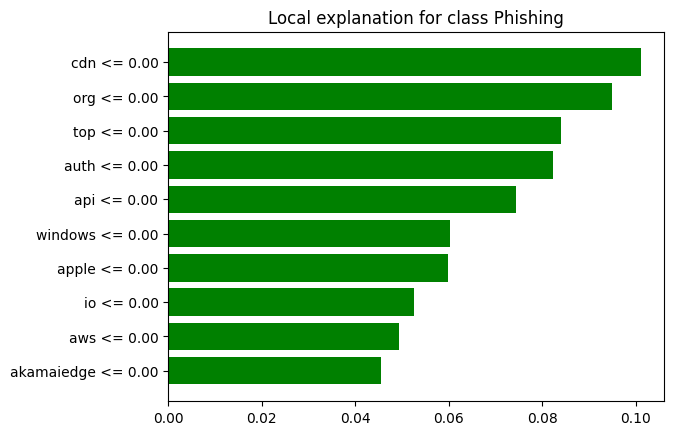

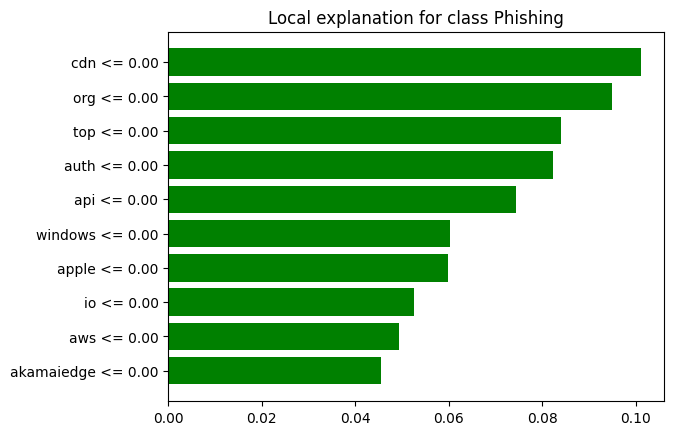

In [258]:
exp.as_pyplot_figure()

In [259]:
print(exp.score)

0.08823444276169523


In [260]:
print(exp.local_pred)

print(exp.predict_proba)

[0.9639698]
[0.48339371 0.51660629]


In [261]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():
        fn_counter[feature] += 1

In [262]:
fn_df = pd.DataFrame(

    fn_counter.items(),

    columns=["Feature","Frequency"]

)

fn_df = fn_df.sort_values(

    "Frequency",

    ascending=False

)

fn_df.head(20)

,Feature,Frequency
1,org <= 0.00,213
5,api <= 0.00,200
8,cdn <= 0.00,195
0,casalemedia <= 0.00,116
10,assets <= 0.00,103
2,top <= 0.00,85
13,cloud <= 0.00,83
3,media <= 0.00,77
26,tv <= 0.00,73
12,sn <= 0.00,65


In [263]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(

        X_test_dense[idx],

        SV3_tuned.predict_proba,

        num_features=10
    )

    for feature, weight in exp.as_list():

        fp_counter[feature] += 1

In [264]:
fp_df = pd.DataFrame(

    fp_counter.items(),

    columns=["Feature","Frequency"]

)

fp_df = fp_df.sort_values(

    "Frequency",

    ascending=False
)

fp_df.head(20)

,Feature,Frequency
2,api <= 0.00,10
3,org <= 0.00,10
5,cdn <= 0.00,8
19,cloud <= 0.00,6
15,casalemedia <= 0.00,5
22,appsflyersdk <= 0.00,4
20,blob <= 0.00,4
1,assets <= 0.00,4
21,cn <= 0.00,4
0,media <= 0.00,3


In [265]:
comparison = pd.merge(

    fn_df,

    fp_df,

    on="Feature",

    how="outer",

    suffixes=("_FN","_FP")

).fillna(0)

comparison = comparison.sort_values(

    "Frequency_FN",

    ascending=False
)

comparison.head(20)

,Feature,Frequency_FN,Frequency_FP
84,org <= 0.00,213.0,10.0
11,api <= 0.00,200.0,10.0
27,cdn <= 0.00,195.0,8.0
24,casalemedia <= 0.00,116.0,5.0
14,assets <= 0.00,103.0,4.0
106,top <= 0.00,85.0,3.0
33,cloud <= 0.00,83.0,6.0
76,media <= 0.00,77.0,3.0
107,tv <= 0.00,73.0,3.0
101,sn <= 0.00,65.0,0.0


FN Predicted Probabilities: [0.48339371 0.51660629]
FN Explanation Score: 0.07897572425151556


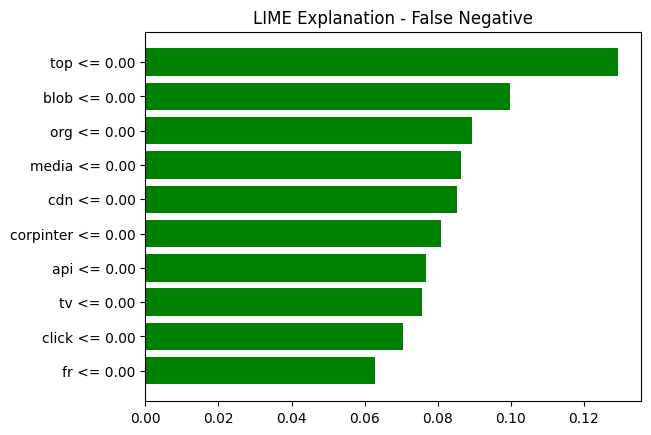

In [266]:
# First False Negative
fn_sample = fn_idx[0]

exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

print("FN Predicted Probabilities:", exp_fn.predict_proba)
print("FN Explanation Score:", exp_fn.score)

fig = exp_fn.as_pyplot_figure()
plt.title("LIME Explanation - False Negative")
plt.show()

FP Predicted Probabilities: [0.35656741 0.64343259]
FP Explanation Score: 0.07716067309377606


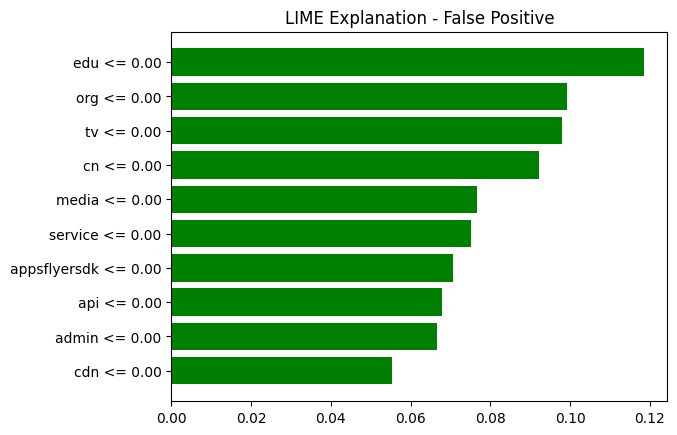

In [267]:
# First False Positive
fp_sample = fp_idx[0]

exp_fp = explainer.explain_instance(
    X_test_dense[fp_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

print("FP Predicted Probabilities:", exp_fp.predict_proba)
print("FP Explanation Score:", exp_fp.score)

fig = exp_fp.as_pyplot_figure()
plt.title("LIME Explanation - False Positive")
plt.show()

In [268]:
# Select one False Negative
fn_sample = fn_idx[0]

exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

In [269]:
exp_fn.show_in_notebook(show_table=True)

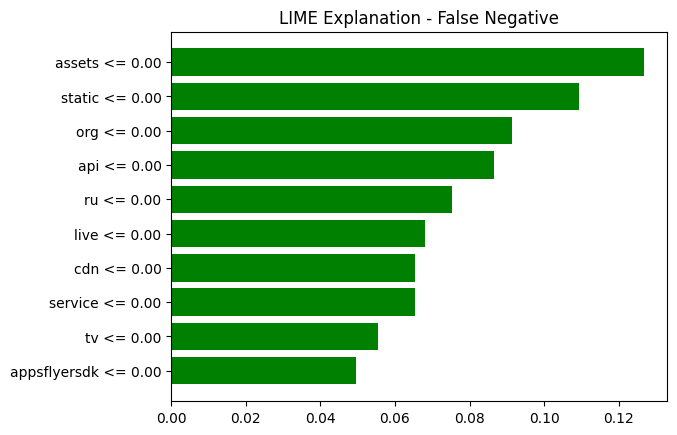

In [270]:
import matplotlib.pyplot as plt

exp_fn.as_pyplot_figure()
plt.title("LIME Explanation - False Negative")
plt.show()

In [271]:
fn_feature_table = pd.DataFrame(
    exp_fn.as_list(),
    columns=["Feature", "Weight"]
)

fn_feature_table

,Feature,Weight
0,assets <= 0.00,0.126734
1,static <= 0.00,0.109321
2,org <= 0.00,0.091499
3,api <= 0.00,0.086640
4,ru <= 0.00,0.075241
5,live <= 0.00,0.068010
6,cdn <= 0.00,0.065379
7,service <= 0.00,0.065327
8,tv <= 0.00,0.055567
9,appsflyersdk <= 0.00,0.049496


In [272]:
fn_feature_table.to_csv(
    "LIME_FN_Feature_Table.csv",
    index=False
)

In [273]:
fp_sample = fp_idx[0]

exp_fp = explainer.explain_instance(
    X_test_dense[fp_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

In [274]:
exp_fp.show_in_notebook(show_table=True)

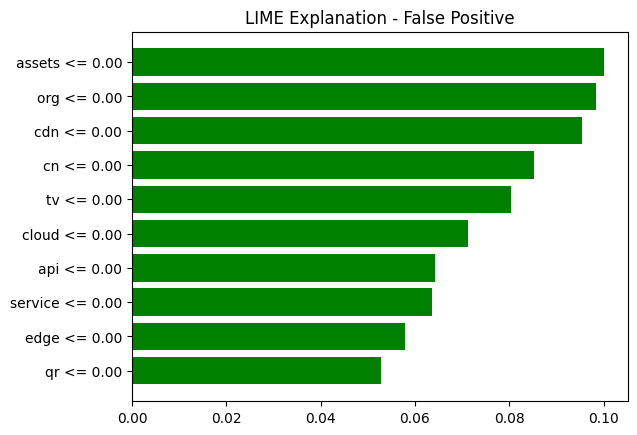

In [275]:
exp_fp.as_pyplot_figure()

plt.title("LIME Explanation - False Positive")

plt.show()

In [276]:
fp_feature_table = pd.DataFrame(
    exp_fp.as_list(),
    columns=["Feature", "Weight"]
)

fp_feature_table

,Feature,Weight
0,assets <= 0.00,0.100155
1,org <= 0.00,0.098316
2,cdn <= 0.00,0.095493
3,cn <= 0.00,0.085206
4,tv <= 0.00,0.080395
5,cloud <= 0.00,0.071196
6,api <= 0.00,0.064253
7,service <= 0.00,0.063667
8,edge <= 0.00,0.057787
9,qr <= 0.00,0.052861


In [277]:
fp_feature_table.to_csv(
    "LIME_FP_Feature_Table.csv",
    index=False
)

In [278]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():

        fn_counter[feature] += 1

In [279]:
fn_df = pd.DataFrame(
    fn_counter.items(),
    columns=["Feature","Frequency"]
)

fn_df = fn_df.sort_values(
    "Frequency",
    ascending=False
)

fn_df.head(20)

,Feature,Frequency
11,org <= 0.00,206
5,api <= 0.00,201
4,cdn <= 0.00,201
1,casalemedia <= 0.00,108
35,top <= 0.00,94
10,assets <= 0.00,87
25,cloud <= 0.00,79
41,tv <= 0.00,74
42,sn <= 0.00,62
34,media <= 0.00,60


In [280]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():

        fp_counter[feature] += 1

In [281]:
fp_df = pd.DataFrame(
    fp_counter.items(),
    columns=["Feature","Frequency"]
)

fp_df = fp_df.sort_values(
    "Frequency",
    ascending=False
)

fp_df.head(20)

,Feature,Frequency
3,org <= 0.00,10
0,cdn <= 0.00,9
6,api <= 0.00,9
5,assets <= 0.00,6
15,tv <= 0.00,5
21,casalemedia <= 0.00,5
19,cloud <= 0.00,4
4,top <= 0.00,4
12,appsflyersdk <= 0.00,3
35,fr <= 0.00,3


In [282]:
comparison = pd.merge(
    fn_df,
    fp_df,
    on="Feature",
    how="outer",
    suffixes=("_FN","_FP")
).fillna(0)

comparison = comparison.sort_values(
    "Frequency_FN",
    ascending=False
)

comparison.head(20)

,Feature,Frequency_FN,Frequency_FP
82,org <= 0.00,206.0,10.0
23,cdn <= 0.00,201.0,9.0
11,api <= 0.00,201.0,9.0
22,casalemedia <= 0.00,108.0,5.0
108,top <= 0.00,94.0,4.0
14,assets <= 0.00,87.0,6.0
29,cloud <= 0.00,79.0,4.0
109,tv <= 0.00,74.0,5.0
103,sn <= 0.00,62.0,2.0
74,media <= 0.00,60.0,2.0


In [283]:
comparison.to_csv(
    "LIME_FP_FN_Comparison.csv",
    index=False
)

In [284]:
exp = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=20,
    top_labels=2
)

print(exp.available_labels())

print("Legitimate")
print(exp.as_list(label=0))

print("Phishing")
print(exp.as_list(label=1))

[np.int64(1), np.int64(0)]
Legitimate
[('org <= 0.00', -0.10224067687048179), ('cdn <= 0.00', -0.08686257056351676), ('media <= 0.00', -0.08332899036779562), ('tv <= 0.00', -0.07860966811144014), ('prd <= 0.00', -0.0784244368027915), ('assets <= 0.00', -0.06967521404132071), ('eu1 <= 0.00', -0.06937066714857301), ('api <= 0.00', -0.06782485349543663), ('wixsite <= 0.00', -0.06754834797795833), ('apple <= 0.00', -0.06667302816991316), ('casalemedia <= 0.00', -0.06238844535374695), ('top <= 0.00', -0.06217169722221884), ('scl <= 0.00', -0.05873396129267547), ('azure <= 0.00', -0.05765636244167183), ('sharepoint <= 0.00', -0.056612991248680876), ('edge <= 0.00', -0.05598507367781557), ('ch <= 0.00', -0.054345254768195114), ('ap <= 0.00', -0.05116922324483774), ('prod <= 0.00', -0.04878920584663975), ('qr <= 0.00', -0.042368440881715985)]
Phishing
[('org <= 0.00', 0.10224067687048181), ('cdn <= 0.00', 0.08686257056351676), ('media <= 0.00', 0.0833289903677956), ('tv <= 0.00', 0.07860966811

In [285]:
print(X_train_200.shape)
print(len(feature_names_200))

(78957, 200)
200


In [286]:
print(feature_names_200[:50])

['num_slashes' 'com' 'url_length' 'num_digits' 'num_question_marks'
 'num_equal' 'google' 'net' 'num_ampersands' 'pub' 'docs'
 'num_underscores' 'start' 'presentation' 'de' 'loop' 'delayms' '2pacx'
 '3000' 'amp' 'num_dots' 'false' 'app' 'qrco' 'me' 'weebly' 'to' 'ead'
 'html' 'dev' 'io' 'id' 'num_hyphens' 'sn' 'web' 'prod' 'us' 'api' 'ly'
 'firebaseapp' 'bit' 'r2' 'co' 'googlevideo' 'php' 'index' 'cdn' 'org'
 'slide' 'ipfs']


In [287]:
print(feature_names_200[-20:])

['3a' 'nflxvideo' 'ukit' 'practice' 'admin' '01' 'bio' 'ap' 'akamaiedge'
 'support' 'it' 'godaddysites' 'ch' 'akadns' 'ix' 'blob' 'oca' 'github'
 '2mdn' 'corpinter']


In [288]:
import numpy as np

fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]
fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]

print("False Negatives :", len(fn_idx))
print("False Positives :", len(fp_idx))

False Negatives : 218
False Positives : 10


In [289]:
fn_probs = y_prob[fn_idx,0]

fn_sample = fn_idx[np.argmax(fn_probs)]

print(fn_sample)

6641


In [290]:
fp_probs = y_prob[fp_idx,1]

fp_sample = fp_idx[np.argmax(fp_probs)]

print(fp_sample)

28684


In [291]:
exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    labels=(0,1),
    num_features=15
)

In [292]:
print("Prediction Probabilities")

print("Legitimate :", exp_fn.predict_proba[0])

print("Phishing   :", exp_fn.predict_proba[1])

Prediction Probabilities
Legitimate : 0.6666651564750906
Phishing   : 0.33333484352490944


In [293]:
exp_fn.show_in_notebook(show_table=True)

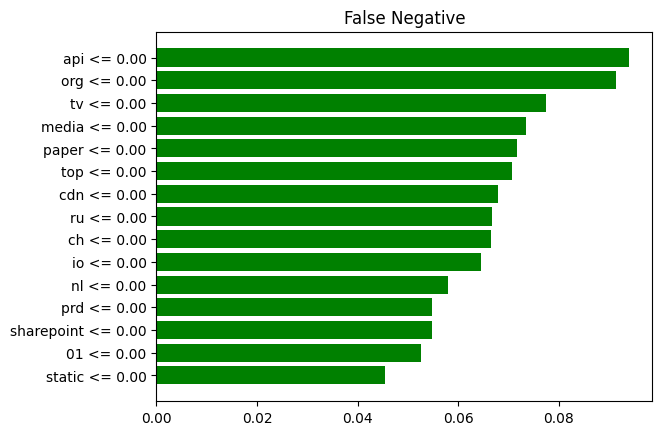

In [294]:
import matplotlib.pyplot as plt

exp_fn.as_pyplot_figure()

plt.title("False Negative")

plt.show()

In [295]:
legitimate_features = pd.DataFrame(
    exp_fn.as_list(label=0),
    columns=["Feature","Weight"]
)

phishing_features = pd.DataFrame(
    exp_fn.as_list(label=1),
    columns=["Feature","Weight"]
)

In [296]:
print("Legitimate Supporting Features")

display(legitimate_features)

print("Phishing Supporting Features")

display(phishing_features)

Legitimate Supporting Features


,Feature,Weight
0,api <= 0.00,-0.093859
1,org <= 0.00,-0.091297
2,tv <= 0.00,-0.077475
3,media <= 0.00,-0.073519
4,paper <= 0.00,-0.071702
5,top <= 0.00,-0.070612
6,cdn <= 0.00,-0.067943
7,ru <= 0.00,-0.066769
8,ch <= 0.00,-0.066453
9,io <= 0.00,-0.064442


Phishing Supporting Features


,Feature,Weight
0,api <= 0.00,0.093859
1,org <= 0.00,0.091297
2,tv <= 0.00,0.077475
3,media <= 0.00,0.073519
4,paper <= 0.00,0.071702
5,top <= 0.00,0.070612
6,cdn <= 0.00,0.067943
7,ru <= 0.00,0.066769
8,ch <= 0.00,0.066453
9,io <= 0.00,0.064442


In [297]:
feature_values = pd.DataFrame({

    "Feature":feature_names_200,

    "Value":X_test_dense[fn_sample]

})

feature_values.head(20)

,Feature,Value
0,num_slashes,-0.629497
1,com,0.000000
2,url_length,-0.072848
3,num_digits,-0.253520
4,num_question_marks,-0.307097
5,num_equal,-0.232059
6,google,0.000000
7,net,1.000000
8,num_ampersands,-0.191205
9,pub,0.000000


In [298]:
exp_fp = explainer.explain_instance(
    X_test_dense[fp_sample],
    SV3_tuned.predict_proba,
    labels=(0,1),
    num_features=15
)

In [299]:
print("Prediction Probabilities")

print("Legitimate :", exp_fp.predict_proba[0])

print("Phishing   :", exp_fp.predict_proba[1])

Prediction Probabilities
Legitimate : 0.05111665888712091
Phishing   : 0.9488833411128791


In [300]:
exp_fp.show_in_notebook(show_table=True)

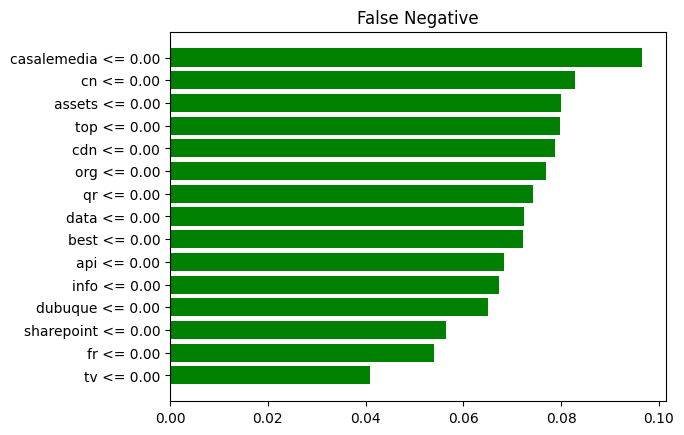

In [301]:
import matplotlib.pyplot as plt

exp_fp.as_pyplot_figure()

plt.title("False Negative")

plt.show()

In [302]:
legitimate_features = pd.DataFrame(
    exp_fp.as_list(label=0),
    columns=["Feature","Weight"]
)

phishing_features = pd.DataFrame(
    exp_fp.as_list(label=1),
    columns=["Feature","Weight"]
)

In [303]:
print("Legitimate Supporting Features")

display(legitimate_features)

print("Phishing Supporting Features")

display(phishing_features)

Legitimate Supporting Features


,Feature,Weight
0,casalemedia <= 0.00,-0.096650
1,cn <= 0.00,-0.082894
2,assets <= 0.00,-0.080005
3,top <= 0.00,-0.079773
4,cdn <= 0.00,-0.078764
5,org <= 0.00,-0.076953
6,qr <= 0.00,-0.074213
7,data <= 0.00,-0.072356
8,best <= 0.00,-0.072299
9,api <= 0.00,-0.068293


Phishing Supporting Features


,Feature,Weight
0,casalemedia <= 0.00,0.096650
1,cn <= 0.00,0.082894
2,assets <= 0.00,0.080005
3,top <= 0.00,0.079773
4,cdn <= 0.00,0.078764
5,org <= 0.00,0.076953
6,qr <= 0.00,0.074213
7,data <= 0.00,0.072356
8,best <= 0.00,0.072299
9,api <= 0.00,0.068293


In [304]:
feature_values = pd.DataFrame({

    "Feature":feature_names_200,

    "Value":X_test_dense[fp_sample]

})

feature_values.head(20)

,Feature,Value
0,num_slashes,-0.629497
1,com,0.000000
2,url_length,-0.005127
3,num_digits,-0.253520
4,num_question_marks,-0.307097
5,num_equal,-0.232059
6,google,0.000000
7,net,0.000000
8,num_ampersands,-0.191205
9,pub,0.000000


In [305]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for f,w in exp.as_list():

        fn_counter[f]+=1

In [306]:
fn_df = pd.DataFrame(

    fn_counter.items(),

    columns=["Feature","Frequency"]

).sort_values("Frequency",ascending=False)

fn_df

,Feature,Frequency
3,org <= 0.00,212
9,api <= 0.00,207
5,cdn <= 0.00,194
8,casalemedia <= 0.00,122
11,assets <= 0.00,102
...,...,...
117,cc <= 0.00,1
118,cdn > 0.00,1
119,rr1 <= 0.00,1
120,auth > 0.00,1


In [307]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for f,w in exp.as_list():

        fp_counter[f]+=1

In [308]:
fp_df = pd.DataFrame(

    fp_counter.items(),

    columns=["Feature","Frequency"]

).sort_values("Frequency",ascending=False)

fp_df

,Feature,Frequency
1,org <= 0.00,10
4,api <= 0.00,10
14,cdn <= 0.00,7
3,casalemedia <= 0.00,5
6,tv <= 0.00,5
9,cloud <= 0.00,5
19,assets <= 0.00,4
26,static <= 0.00,4
12,top <= 0.00,4
5,sharepoint <= 0.00,3


In [309]:
from collections import defaultdict
import numpy as np
import pandas as pd

feature_frequency = defaultdict(int)
feature_weight = defaultdict(float)

# Combine False Negative and False Positive indices
all_error_idx = np.concatenate([fn_idx, fp_idx])

print("Total error samples:", len(all_error_idx))

for sample in all_error_idx:

    exp = explainer.explain_instance(
        X_test_dense[sample],
        SV3_tuned.predict_proba,
        num_features=15
    )

    # Explanation for phishing class (class 1)
    for feature_idx, weight in exp.as_map()[1]:

        feature_frequency[feature_idx] += 1
        feature_weight[feature_idx] += abs(weight)

print("LIME analysis completed.")
print("Number of features found:", len(feature_frequency))

Total error samples: 228
LIME analysis completed.
Number of features found: 129


In [310]:
importance_df = pd.DataFrame({
    "Feature_Index": list(feature_frequency.keys()),
    "Frequency": [feature_frequency[i] for i in feature_frequency],
    "Total_LIME_Weight": [feature_weight[i] for i in feature_frequency]
})

importance_df["Average_LIME_Weight"] = (
    importance_df["Total_LIME_Weight"] /
    importance_df["Frequency"]
)

importance_df["Feature"] = importance_df["Feature_Index"].apply(
    lambda i: feature_names_200[i]
)

importance_df = importance_df.sort_values(
    "Total_LIME_Weight",
    ascending=False
)

importance_df.head(20)

,Feature_Index,Frequency,Total_LIME_Weight,Average_LIME_Weight,Feature
2,47,228,20.727304,0.090909,org
4,37,224,18.233603,0.081400,api
1,46,221,18.171742,0.082225,cdn
0,178,142,11.864794,0.083555,casalemedia
25,146,128,9.946630,0.077708,assets
19,62,133,9.240249,0.069476,cloud
7,33,152,9.102476,0.059885,sn
8,158,122,9.094862,0.074548,top
22,139,103,7.497574,0.072792,media
13,173,100,7.329618,0.073296,tv


In [311]:
stats = []

# Top 20 features according to LIME
top_features = importance_df.head(20)

for _, row in top_features.iterrows():

    feature_name = row["Feature"]
    feature_idx = int(row["Feature_Index"])

    # Check whether feature is present in each test sample
    present = X_test_dense[:, feature_idx] > 0

    TP = np.sum(
        present &
        (y_test == 1) &
        (y_pred == 1)
    )

    TN = np.sum(
        present &
        (y_test == 0) &
        (y_pred == 0)
    )

    FP = np.sum(
        present &
        (y_test == 0) &
        (y_pred == 1)
    )

    FN = np.sum(
        present &
        (y_test == 1) &
        (y_pred == 0)
    )

    stats.append([
        feature_name,
        TP,
        TN,
        FP,
        FN
    ])

stats_df = pd.DataFrame(
    stats,
    columns=[
        "Feature",
        "TP",
        "TN",
        "FP",
        "FN"
    ]
)

stats_df

,Feature,TP,TN,FP,FN
0,org,63,431,0,3
1,api,16,623,0,0
2,cdn,8,426,0,1
3,casalemedia,0,73,0,0
4,assets,17,76,0,0
5,cloud,36,230,0,0
6,sn,6,776,0,0
7,top,21,63,0,0
8,media,15,88,0,0
9,tv,2,82,0,0


In [312]:
final_analysis = pd.merge(
    importance_df,
    stats_df,
    on="Feature",
    how="inner"
)

final_analysis["Errors"] = (
    final_analysis["FP"] +
    final_analysis["FN"]
)

final_analysis["Correct"] = (
    final_analysis["TP"] +
    final_analysis["TN"]
)

final_analysis["Error_Ratio"] = (
    final_analysis["Errors"] /
    (
        final_analysis["Errors"] +
        final_analysis["Correct"]
    )
)

final_analysis = final_analysis.sort_values(
    by=[
        "Error_Ratio",
        "Total_LIME_Weight"
    ],
    ascending=False
)

final_analysis

,Feature_Index,Frequency,Total_LIME_Weight,Average_LIME_Weight,Feature,TP,TN,FP,FN,Errors,Correct,Error_Ratio
14,87,66,4.217367,0.063900,cn,34,172,1,2,3,206,0.014354
11,30,83,4.899996,0.059036,io,635,418,0,11,11,1053,0.010338
0,47,228,20.727304,0.090909,org,63,431,0,3,3,494,0.006036
2,46,221,18.171742,0.082225,cdn,8,426,0,1,1,434,0.002299
13,35,74,4.411937,0.059621,prod,6,613,1,0,1,619,0.001613
16,36,71,4.153922,0.058506,us,154,535,0,1,1,689,0.001449
1,37,224,18.233603,0.081400,api,16,623,0,0,0,639,0.000000
3,178,142,11.864794,0.083555,casalemedia,0,73,0,0,0,73,0.000000
4,146,128,9.946630,0.077708,assets,17,76,0,0,0,93,0.000000
5,62,133,9.240249,0.069476,cloud,36,230,0,0,0,266,0.000000


In [313]:
feature_to_remove = "api"

feature_idx = int(
    final_analysis.loc[
        final_analysis["Feature"] == feature_to_remove,
        "Feature_Index"
    ].iloc[0]
)

print("Feature:", feature_to_remove)
print("Index:", feature_idx)

Feature: api
Index: 37


In [314]:
keep_idx = np.delete(
    np.arange(X_train_200.shape[1]),
    feature_idx
)

X_train_199 = X_train_200[:, keep_idx]
X_test_199 = X_test_200[:, keep_idx]

print("Original:", X_train_200.shape)
print("After removal:", X_train_199.shape)
print("Test after removal:", X_test_199.shape)

Original: (78957, 200)
After removal: (78957, 199)
Test after removal: (33839, 199)


In [315]:
from sklearn.base import clone

SV3_refined = clone(SV3_tuned)

SV3_refined.fit(
    X_train_199,
    y_train
)

,estimators,"[('rf', ...), ('mlp', ...), ...]"
,voting,'soft'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1


In [316]:
print(X_train_199.shape)
print(X_test_199.shape)
print(y_train.shape)
print(y_test.shape)

(78957, 199)
(33839, 199)
(78957,)
(33839,)


In [317]:
print(SV3_tuned)

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(min_samples_split=5,
                                                     n_estimators=200,
                                                     random_state=42)),
                             ('mlp',
                              MLPClassifier(alpha=0.001,
                                            hidden_layer_sizes=(100, 50),
                                            max_iter=300, random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            e...
                                            feature_weights=None, 

In [318]:
y_pred_refined = SV3_refined.predict(X_test_199)

y_prob_refined = SV3_refined.predict_proba(X_test_199)[:, 1]

In [319]:
X_train_199
X_test_199

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 421042 stored elements and shape (33839, 199)>

In [320]:
# Training predictions
y_train_pred_pre = SV3_tuned.predict(X_train_200)
y_train_prob_pre = SV3_tuned.predict_proba(X_train_200)[:, 1]

train_acc_pre = accuracy_score(y_train, y_train_pred_pre)
train_f1_pre = f1_score(y_train, y_train_pred_pre)
train_auc_pre = roc_auc_score(y_train, y_train_prob_pre)
train_mcc_pre = matthews_corrcoef(y_train, y_train_pred_pre)
train_prec_pre = precision_score(y_train, y_train_pred_pre)
train_rec_pre = recall_score(y_train, y_train_pred_pre)

tn_pre, fp_pre, fn_pre, tp_pre = confusion_matrix(
    y_train, y_train_pred_pre
).ravel()

In [321]:
y_train_pred_post = SV3_refined.predict(X_train_199)
y_train_prob_post = SV3_refined.predict_proba(X_train_199)[:, 1]

train_acc_post = accuracy_score(y_train, y_train_pred_post)
train_f1_post = f1_score(y_train, y_train_pred_post)
train_auc_post = roc_auc_score(y_train, y_train_prob_post)
train_mcc_post = matthews_corrcoef(y_train, y_train_pred_post)
train_prec_post = precision_score(y_train, y_train_pred_post)
train_rec_post = recall_score(y_train, y_train_pred_post)

tn_post, fp_post, fn_post, tp_post = confusion_matrix(
    y_train, y_train_pred_post
).ravel()

In [322]:
y_test_pred_pre = SV3_tuned.predict(X_test_200)
y_test_prob_pre = SV3_tuned.predict_proba(X_test_200)[:, 1]

test_acc_pre = accuracy_score(y_test, y_test_pred_pre)
test_f1_pre = f1_score(y_test, y_test_pred_pre)
test_auc_pre = roc_auc_score(y_test, y_test_prob_pre)
test_mcc_pre = matthews_corrcoef(y_test, y_test_pred_pre)
test_prec_pre = precision_score(y_test, y_test_pred_pre)
test_rec_pre = recall_score(y_test, y_test_pred_pre)

tn_pre_test, fp_pre_test, fn_pre_test, tp_pre_test = confusion_matrix(
    y_test, y_test_pred_pre
).ravel()

In [323]:
y_test_pred_post = SV3_refined.predict(X_test_199)
y_test_prob_post = SV3_refined.predict_proba(X_test_199)[:, 1]

test_acc_post = accuracy_score(y_test, y_test_pred_post)
test_f1_post = f1_score(y_test, y_test_pred_post)
test_auc_post = roc_auc_score(y_test, y_test_prob_post)
test_mcc_post = matthews_corrcoef(y_test, y_test_pred_post)
test_prec_post = precision_score(y_test, y_test_pred_post)
test_rec_post = recall_score(y_test, y_test_pred_post)

tn_post_test, fp_post_test, fn_post_test, tp_post_test = confusion_matrix(
    y_test, y_test_pred_post
).ravel()

In [324]:
train_table = pd.DataFrame({
    "Model (SV3)": ["Pre-Explainable AI", "Post-Explainable AI"],
    "Train_Accuracy (%)": [train_acc_pre*100, train_acc_post*100],
    "F1-Score": [train_f1_pre, train_f1_post],
    "AUC": [train_auc_pre, train_auc_post],
    "MCC": [train_mcc_pre, train_mcc_post],
    "Precision (Phishing)": [train_prec_pre, train_prec_post],
    "Recall (Phishing)": [train_rec_pre, train_rec_post],
    "TP": [tp_pre, tp_post],
    "FP": [fp_pre, fp_post],
    "TN": [tn_pre, tn_post],
    "FN": [fn_pre, fn_post]
})

train_table

,Model (SV3),Train_Accuracy (%),F1-Score,AUC,MCC,Precision (Phishing),Recall (Phishing),TP,FP,TN,FN
0,Pre-Explainable AI,99.504794,0.995025,0.999582,0.990137,0.999591,0.990501,39104,16,39462,375
1,Post-Explainable AI,99.511126,0.995089,0.999570,0.990263,0.999642,0.990577,39107,14,39464,372


In [325]:
test_table = pd.DataFrame({
    "Model (SV3)": ["Pre-Explainable AI", "Post-Explainable AI"],
    "Test_Accuracy (%)": [test_acc_pre*100, test_acc_post*100],
    "F1-Score": [test_f1_pre, test_f1_post],
    "AUC": [test_auc_pre, test_auc_post],
    "MCC": [test_mcc_pre, test_mcc_post],
    "Precision (Phishing)": [test_prec_pre, test_prec_post],
    "Recall (Phishing)": [test_rec_pre, test_rec_post],
   "TP": [tp_pre_test, tp_post_test],
    "FP": [fp_pre_test, fp_post_test],
    "TN": [tn_pre_test, tn_post_test],
    "FN": [fn_pre_test, fn_post_test]
})

test_table

,Model (SV3),Test_Accuracy (%),F1-Score,AUC,MCC,Precision (Phishing),Recall (Phishing),TP,FP,TN,FN
0,Pre-Explainable AI,99.326221,0.99322,0.998362,0.986599,0.999402,0.987115,16701,10,16910,218
1,Post-Explainable AI,99.320311,0.99316,0.998346,0.986484,0.999461,0.986938,16698,9,16911,221


In [326]:
y_train_pred = SV3_tuned.predict(X_train_200)

In [327]:
print(X_train_200.shape)
print(X_test_200.shape)

print(len(y_train))
print(len(y_test))

(78957, 200)
(33839, 200)
78957
33839


In [328]:
print(len(y_train_pred_pre))
print(len(y_train))

78957
78957


In [329]:
print(len(y_test_pred_pre))
print(len(y_test))

33839
33839


In [330]:
cm = confusion_matrix(y_test, y_test_pred_pre)

print(cm)

print(cm.sum())

[[16910    10]
 [  218 16701]]
33839


In [331]:
print(SV3_tuned)

print(type(X_train_200))
print(X_train_200.shape)

print(type(X_test_200))
print(X_test_200.shape)

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(min_samples_split=5,
                                                     n_estimators=200,
                                                     random_state=42)),
                             ('mlp',
                              MLPClassifier(alpha=0.001,
                                            hidden_layer_sizes=(100, 50),
                                            max_iter=300, random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            e...
                                            feature_weights=None, 

In [332]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [333]:
print(SV3_tuned.estimators_)

[RandomForestClassifier(min_samples_split=5, n_estimators=200, random_state=42), MLPClassifier(alpha=0.001, hidden_layer_sizes=(100, 50), max_iter=300,
              random_state=42), XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)]


In [334]:
X_train_dense = X_train_200.toarray()

X_test_dense = X_test_200.toarray()

In [335]:
print(X_train_dense.shape)
print(X_test_dense.shape)

(78957, 200)
(33839, 200)


In [336]:
background = shap.sample(
    X_train_dense,
    100,
    random_state=42
)

In [337]:
predict_fn = lambda x: SV3_tuned.predict_proba(x)

In [338]:
predict_fn(background).shape

(100, 2)

In [339]:
explainer = shap.KernelExplainer(
    predict_fn,
    background
)

In [340]:
X_sample = X_test_dense[:500]

In [341]:
shap_values = explainer.shap_values(
    X_sample
)

  0%|          | 0/500 [00:00<?, ?it/s]

In [342]:
print(type(shap_values))

if isinstance(shap_values,list):

    print(len(shap_values))

    print(shap_values[1].shape)

else:

    print(shap_values.shape)

<class 'numpy.ndarray'>
(500, 200, 2)


In [344]:
print(type(shap_values))
print(np.array(shap_values).shape)
print(X_sample.shape)
print(background.shape)
print(len(feature_names_200))

<class 'numpy.ndarray'>
(500, 200, 2)
(500, 200)
(100, 200)
200


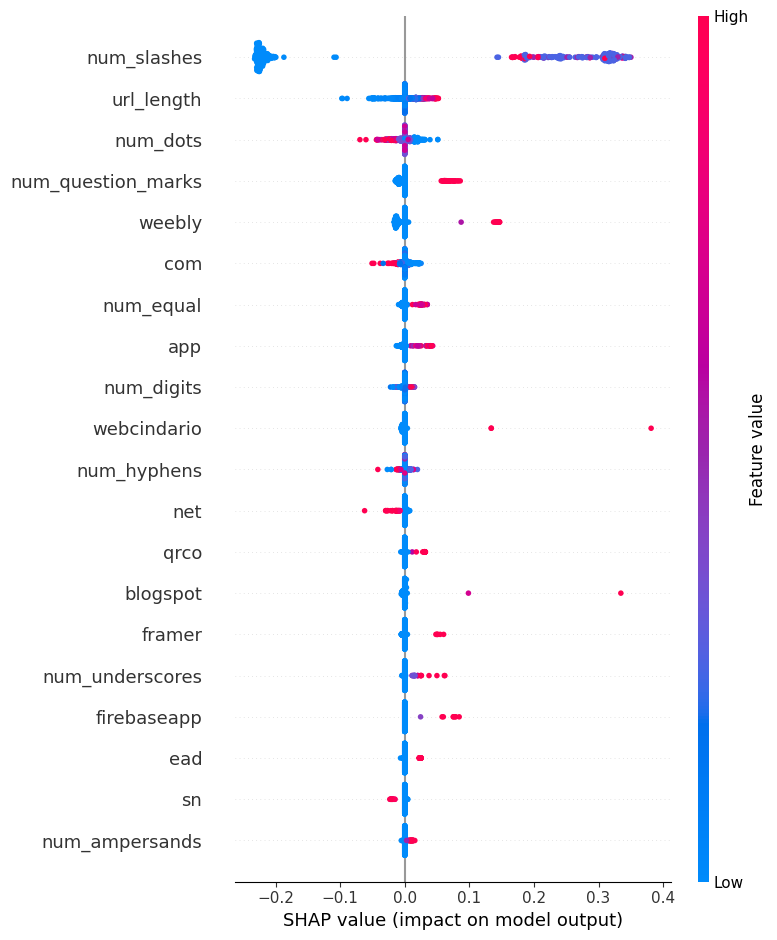

In [345]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    feature_names=feature_names_200
)

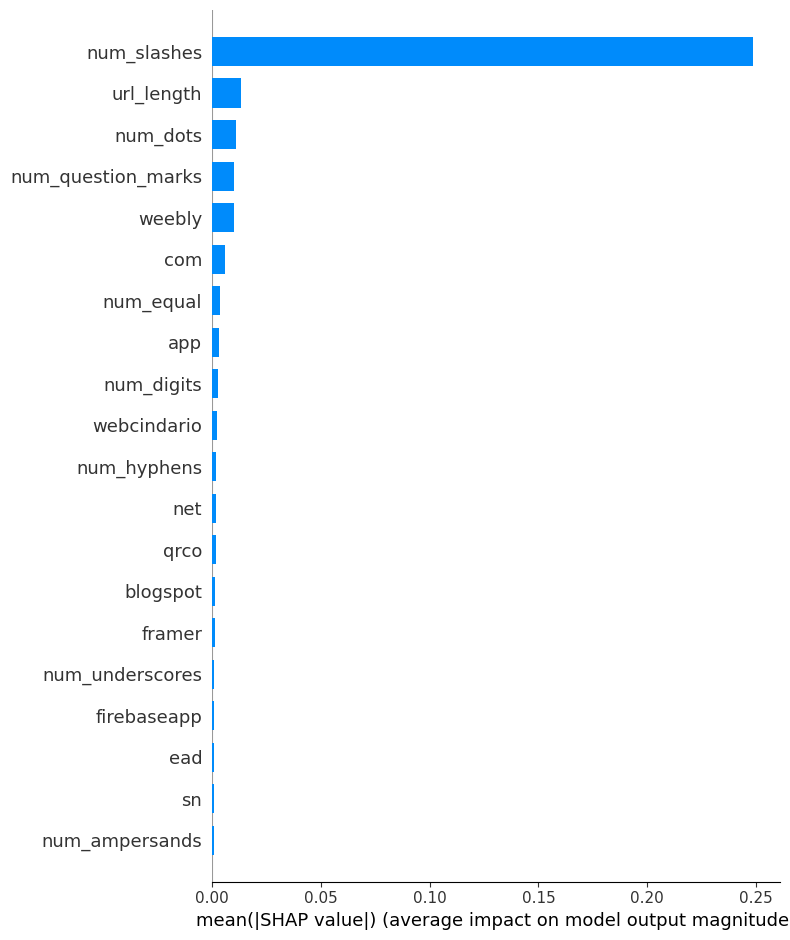

In [348]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    feature_names=feature_names_200,
    plot_type="bar"
)

In [349]:
mean_shap = np.abs(
    shap_values[:, :, 1]
).mean(axis=0)

In [350]:
print(type(shap_values))
print(len(shap_values))
print(type(shap_values[0]))
print(shap_values[0].shape)
print(shap_values[1].shape)

<class 'numpy.ndarray'>
500
<class 'numpy.ndarray'>
(200, 2)
(200, 2)


In [352]:
mean_shap = np.abs(shap_values[:, :, 1]).mean(axis=0)

In [353]:
shap_df = pd.DataFrame({
    "Feature": feature_names_200,
    "Mean_SHAP": mean_shap
})

shap_df = shap_df.sort_values(
    "Mean_SHAP",
    ascending=False
)

shap_df.head(20)

,Feature,Mean_SHAP
0,num_slashes,0.248490
2,url_length,0.013496
20,num_dots,0.011135
4,num_question_marks,0.010377
25,weebly,0.010367
1,com,0.006022
5,num_equal,0.003516
22,app,0.003097
3,num_digits,0.002628
68,webcindario,0.002240


In [354]:
TOP_N = 20

shap_top20 = shap_df.head(TOP_N)

shap_top20

,Feature,Mean_SHAP
0,num_slashes,0.248490
2,url_length,0.013496
20,num_dots,0.011135
4,num_question_marks,0.010377
25,weebly,0.010367
1,com,0.006022
5,num_equal,0.003516
22,app,0.003097
3,num_digits,0.002628
68,webcindario,0.002240


In [355]:
from collections import Counter

fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]

fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]

print("False Negatives :", len(fn_idx))
print("False Positives :", len(fp_idx))

False Negatives : 218
False Positives : 10


In [356]:
all_error_idx = np.concatenate([fn_idx, fp_idx])

print("Total Error Samples :", len(all_error_idx))

Total Error Samples : 228


In [357]:
from collections import defaultdict

feature_frequency = defaultdict(int)
feature_weight = defaultdict(float)

In [358]:
from lime.lime_tabular import LimeTabularExplainer
from collections import defaultdict
import numpy as np
import pandas as pd

In [359]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_dense,
    feature_names=feature_names_200,
    class_names=["Legitimate", "Phishing"],
    mode="classification",
    random_state=42
)

In [360]:
LIME_SAMPLE_SIZE = 500

sample_indices = np.random.RandomState(42).choice(
    len(X_test_dense),
    size=LIME_SAMPLE_SIZE,
    replace=False
)

In [361]:
feature_frequency = defaultdict(int)

feature_total_weight = defaultdict(float)

In [362]:
import re

def clean_feature_name(feature):
    feature = str(feature)
    # strip a leading "number <" or "number <=" (e.g. "0.05 < api" -> "api")
    feature = re.sub(r'^-?\d+\.?\d*\s*[<>]=?\s*', '', feature)
    # strip a trailing "<= number" or "> number" (e.g. "api <= 0.10" -> "api")
    feature = re.sub(r'\s*[<>]=?\s*-?\d+\.?\d*$', '', feature)
    return feature.strip()

for idx in sample_indices:

    exp = lime_explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=20
    )

    for feature, weight in exp.as_list():

        clean_feature = clean_feature_name(feature)

        feature_frequency[clean_feature] += 1

        feature_total_weight[clean_feature] += abs(weight)

In [363]:
lime_df = pd.DataFrame({

    "Feature": list(feature_frequency.keys()),

    "Frequency": list(feature_frequency.values()),

    "Total_LIME_Weight":[
        feature_total_weight[f]
        for f in feature_frequency
    ]

})

In [364]:
lime_df["Average_LIME_Weight"] = (

    lime_df["Total_LIME_Weight"] /

    lime_df["Frequency"]

)

In [365]:
lime_df = lime_df.sort_values(

    "Total_LIME_Weight",

    ascending=False

)

lime_df.head(20)

,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
2,org,500,45.352446,0.090705
7,api,497,40.126919,0.080738
8,cdn,497,39.856985,0.080195
0,casalemedia,340,26.497717,0.077934
11,sn,442,25.455406,0.057591
20,assets,322,24.046510,0.074679
1,top,304,22.137513,0.072821
22,cloud,344,22.066873,0.064148
6,tv,261,18.633139,0.071391
16,io,322,17.717159,0.055022


In [366]:
TOP_N = 20

lime_top20 = lime_df.head(TOP_N)

lime_top20

,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
2,org,500,45.352446,0.090705
7,api,497,40.126919,0.080738
8,cdn,497,39.856985,0.080195
0,casalemedia,340,26.497717,0.077934
11,sn,442,25.455406,0.057591
20,assets,322,24.046510,0.074679
1,top,304,22.137513,0.072821
22,cloud,344,22.066873,0.064148
6,tv,261,18.633139,0.071391
16,io,322,17.717159,0.055022


In [367]:
from sklearn.inspection import permutation_importance

In [368]:
print(type(X_test_200))

<class 'scipy.sparse._csr.csr_matrix'>


In [369]:
X_test_200_dense = X_test_200.toarray()

In [370]:
perm_result = permutation_importance(
    estimator=SV3_tuned,
    X=X_test_200_dense,
    y=y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [371]:
perm_df = pd.DataFrame({
    "Feature": feature_names_200,
    "Permutation_Importance": perm_result.importances_mean,
    "Permutation_STD": perm_result.importances_std
})

In [372]:
perm_df = perm_df.sort_values(
    by="Permutation_Importance",
    ascending=False
).reset_index(drop=True)

perm_df.head(20)

,Feature,Permutation_Importance,Permutation_STD
0,num_slashes,0.350873,0.002222
1,url_length,0.037436,0.000543
2,num_question_marks,0.021552,0.000445
3,weebly,0.014681,0.000470
4,num_dots,0.011974,0.000622
5,webcindario,0.004244,0.000162
6,num_digits,0.004054,0.000302
7,firebaseapp,0.003330,0.000305
8,has_at_symbol,0.002001,0.000165
9,blogspot,0.001986,0.000119


In [373]:
TOP_N = 20

perm_top20 = perm_df.head(TOP_N)

perm_top20

,Feature,Permutation_Importance,Permutation_STD
0,num_slashes,0.350873,0.002222
1,url_length,0.037436,0.000543
2,num_question_marks,0.021552,0.000445
3,weebly,0.014681,0.000470
4,num_dots,0.011974,0.000622
5,webcindario,0.004244,0.000162
6,num_digits,0.004054,0.000302
7,firebaseapp,0.003330,0.000305
8,has_at_symbol,0.002001,0.000165
9,blogspot,0.001986,0.000119


In [374]:
perm_top20.to_csv(
    "Permutation_Top20.csv",
    index=False
)

perm_df.to_csv(
    "Permutation_AllFeatures.csv",
    index=False
)

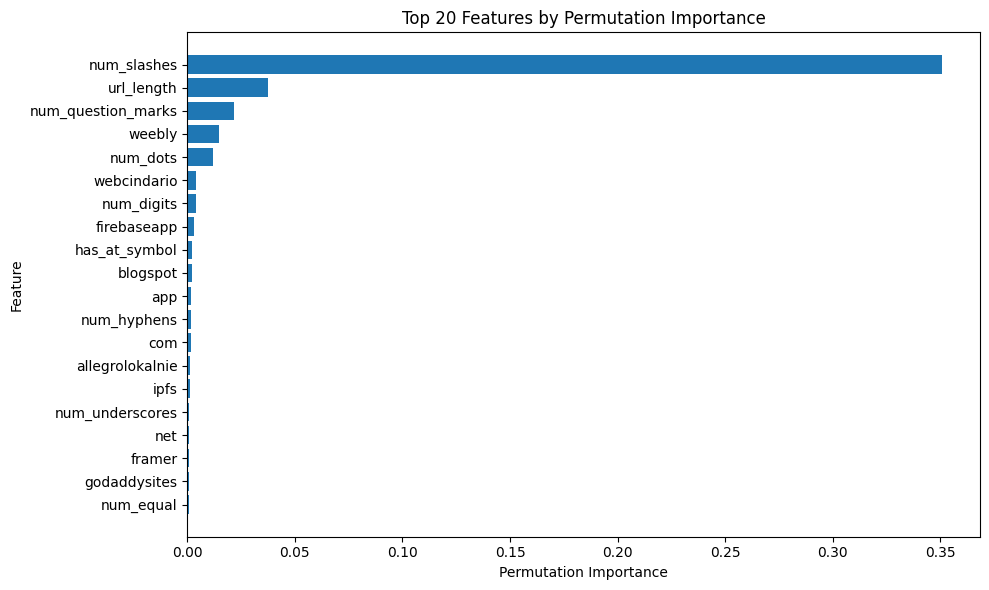

In [375]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    perm_top20["Feature"][::-1],
    perm_top20["Permutation_Importance"][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features by Permutation Importance")

plt.tight_layout()
plt.show()

In [376]:
TOP_N = 20

shap_top20 = shap_df.head(TOP_N).copy()

lime_top20 = lime_df.head(TOP_N).copy()

perm_top20 = perm_df.head(TOP_N).copy()

In [377]:
import re

def clean_feature(feature):
    feature = str(feature)
    # strip a leading "number <" or "number <=" (e.g. "0.05 < api" -> "api")
    feature = re.sub(r'^-?\d+\.?\d*\s*[<>]=?\s*', '', feature)
    # strip a trailing "<= number" or "> number" (e.g. "api <= 0.10" -> "api")
    feature = re.sub(r'\s*[<>]=?\s*-?\d+\.?\d*$', '', feature)
    return feature.strip()

In [378]:
shap_top20["Feature"] = shap_top20["Feature"].apply(clean_feature)

lime_top20["Feature"] = lime_top20["Feature"].apply(clean_feature)

perm_top20["Feature"] = perm_top20["Feature"].apply(clean_feature)

In [379]:
shap_set = set(shap_top20["Feature"])

lime_set = set(lime_top20["Feature"])

perm_set = set(perm_top20["Feature"])

In [380]:
print("SHAP ∩ LIME")
print(shap_set & lime_set)

print()

print("SHAP ∩ Permutation")
print(shap_set & perm_set)

print()

print("LIME ∩ Permutation")
print(lime_set & perm_set)

SHAP ∩ LIME
{'sn'}

SHAP ∩ Permutation
{'net', 'framer', 'com', 'blogspot', 'num_underscores', 'num_digits', 'weebly', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_dots', 'url_length', 'app', 'webcindario', 'num_equal', 'firebaseapp'}

LIME ∩ Permutation
set()


In [381]:
# Sanity check: do the handcrafted feature names actually land on sensible columns?
handcrafted_features = [
    "url_length", "num_dots", "num_digits", "has_at_symbol",
    "num_hyphens", "num_slashes", "num_question_marks",
    "num_equal", "num_underscores", "num_ampersands"
]

for name in handcrafted_features:
    if name in feature_names_200:
        idx = list(feature_names_200).index(name)
        col_values = X_train_dense[:, idx]
        print(f"{name}: min={col_values.min():.2f}, max={col_values.max():.2f}, mean={col_values.mean():.2f}")
    else:
        print(f"{name}: NOT in feature_names_200 (may have been dropped by MI selection)")

url_length: min=-0.33, max=246.39, mean=-0.00
num_dots: min=-0.88, max=43.17, mean=0.00
num_digits: min=-0.25, max=220.76, mean=0.00
has_at_symbol: min=-0.07, max=15.01, mean=-0.00
num_hyphens: min=-0.55, max=25.38, mean=0.00
num_slashes: min=-0.63, max=73.19, mean=0.00
num_question_marks: min=-0.31, max=22.85, mean=0.00
num_equal: min=-0.23, max=38.92, mean=0.00
num_underscores: min=-0.15, max=132.06, mean=-0.00
num_ampersands: min=-0.19, max=48.54, mean=-0.00


In [382]:
# The handcrafted features are the LAST 10 entries in all_feature_names (indices 2000-2009)
handcrafted_indices_original = list(range(2000, 2010))

selected_500_indices = mi_selector.get_support(indices=True)   # indices into the original 2010-dim space

overlap = set(handcrafted_indices_original) & set(selected_500_indices)
print("Handcrafted features kept by MI (500-selection):", len(overlap))
print("Which ones:", [all_feature_names[i] for i in overlap])

Handcrafted features kept by MI (500-selection): 10
Which ones: ['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [383]:
print("top200_idx dtype/shape:", top200_idx.shape, top200_idx.dtype)
print("Max index in top200_idx:", top200_idx.max())
print("X_train shape at the point top200_idx was computed (should be 500):", X_train.shape)

top200_idx dtype/shape: (200,) int64
Max index in top200_idx: 499
X_train shape at the point top200_idx was computed (should be 500): (78957, 500)


In [384]:
print("len(feature_names_200):", len(feature_names_200))
print("len(feature_names_500):", len(feature_names_500))
print("First 10 of feature_names_200:", feature_names_200[:10])
print("Last 10 of feature_names_200:", feature_names_200[-10:])

len(feature_names_200): 200
len(feature_names_500): 500
First 10 of feature_names_200: ['num_slashes' 'com' 'url_length' 'num_digits' 'num_question_marks'
 'num_equal' 'google' 'net' 'num_ampersands' 'pub']
Last 10 of feature_names_200: ['it' 'godaddysites' 'ch' 'akadns' 'ix' 'blob' 'oca' 'github' '2mdn'
 'corpinter']


In [385]:
print("mi_df shape:", mi_df.shape)
print("mi_df columns:", mi_df.columns.tolist())
print(mi_df.head())

mi_df shape: (500, 2)
mi_df columns: ['Feature_Index', 'MI_Score']
     Feature_Index  MI_Score
495            495  0.617354
108            108  0.326951
490            490  0.144223
492            492  0.074335
496            496  0.066889


In [386]:
print("shi")

shi


In [387]:
print("top200_idx shape:", top200_idx.shape)
print("X_train_200 shape:", X_train_200.shape)
print("len(feature_names_200):", len(feature_names_200))
   
for name in ["url_length", "num_dots", "num_digits", "num_hyphens", "num_slashes"]:
       if name in feature_names_200:
           idx = list(feature_names_200).index(name)
           vals = X_train_200[:5, idx]
           vals = vals.toarray().ravel() if hasattr(vals, "toarray") else vals
           print(name, "-> index", idx, "| sample values:", vals)
       else:
           print(name, "-> not in top 200 (plausible now — not a bug)")

top200_idx shape: (200,)
X_train_200 shape: (78957, 200)
len(feature_names_200): 200
url_length -> index 2 | sample values: [-0.15991823 -0.05349914 -0.09219699 -0.17926716 -0.18894162]
num_dots -> index 20 | sample values: [-0.1105788   2.20778818 -0.1105788  -0.1105788  -0.1105788 ]
num_digits -> index 3 | sample values: [-0.25352035 -0.25352035 -0.25352035 -0.25352035 -0.25352035]
num_hyphens -> index 32 | sample values: [ 0.1663978  -0.55386268  0.1663978  -0.55386268  0.1663978 ]
num_slashes -> index 0 | sample values: [-0.62949708 -0.62949708  0.09422703 -0.62949708 -0.62949708]


In [389]:
import sys
!{sys.executable} -m pip install dice-ml

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 32.3 kB/s  0:01:191.0 kB/s eta 0:00:06:36
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 81.6 kB/s  0:01:079.3 kB/s eta 0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [dice-ml]━━━━━━━━━━ 2/3 [dice-ml]

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: /usr/bin/python3 -m pip install --upgrade pip


In [390]:
import dice_ml
from dice_ml import Dice
import pandas as pd

In [392]:
print(type(X_train_200))
print(X_train_200.shape)

print(type(feature_names_200))
print(len(feature_names_200))

<class 'scipy.sparse._csr.csr_matrix'>
(78957, 200)
<class 'numpy.ndarray'>
200


In [393]:
X_train_df = pd.DataFrame(
    X_train_200.toarray(),
    columns=feature_names_200
)

X_test_df = pd.DataFrame(
    X_test_200.toarray(),
    columns=feature_names_200
)

In [394]:
X_train_df["label"] = y_train

In [395]:
continuous_features = feature_names_200.tolist()

In [396]:
import dice_ml

d = dice_ml.Data(
    dataframe=X_train_df,
    continuous_features=continuous_features,
    outcome_name="label"
)

In [397]:
m = dice_ml.Model(model=SV3_tuned, backend="sklearn", model_type="classifier")

In [405]:
exp_kdtree = Dice(d, m, method="kdtree")

In [399]:
# reuse the same samples you ran LIME on, so results are comparable later
dice_sample_indices = sample_indices[:150]  # subsample — genetic search is slow per instance

In [400]:
top_k_for_dice = list(feature_names_200[:50])  # or union of top LIME-flagged features

In [413]:
print("Ggh")

Ggh


In [415]:
exp_genetic_fast = Dice(d, m, method="genetic")

import time
start = time.time()

query_instance = X_test_df.loc[[dice_sample_indices[0]]].drop(columns=["label"], errors="ignore")
cf = exp_genetic_fast.generate_counterfactuals(
    query_instance,
    total_CFs=3,
    desired_class="opposite",
    features_to_vary=top_k_for_dice,
    maxiterations=50,
    verbose=False
)
print("Time taken:", time.time() - start, "seconds")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.42s/it]

Time taken: 5.695777177810669 seconds


In [421]:
import signal, pickle, os
from tqdm.notebook import tqdm

class TimeoutException(Exception):
    pass

def handler(signum, frame):
    raise TimeoutException()

signal.signal(signal.SIGALRM, handler)

cf_results = {}
if os.path.exists("cf_results_checkpoint.pkl"):
    with open("cf_results_checkpoint.pkl", "rb") as f:
        cf_results = pickle.load(f)
    print(f"Resumed: {len(cf_results)} done")

remaining = [idx for idx in dice_sample_indices if idx not in cf_results]
pbar = tqdm(total=len(dice_sample_indices), initial=len(cf_results), desc="DiCE")
start = time.time()

for i, idx in enumerate(remaining):
    query_instance = X_test_df.loc[[idx]].drop(columns=["label"], errors="ignore")
    success = False

    # attempt 1: normal settings, 20s budget
    for attempt, (max_iter, timeout_s) in enumerate([(50, 20), (15, 10)]):
        signal.alarm(timeout_s)
        try:
            cf = exp_genetic_fast.generate_counterfactuals(
                query_instance, total_CFs=3, desired_class="opposite",
                features_to_vary=top_k_for_dice, maxiterations=max_iter, verbose=False
            )
            signal.alarm(0)
            cf_results[idx] = cf
            success = True
            break
        except TimeoutException:
            continue
        except Exception as e:
            signal.alarm(0)
            break

    if not success:
        print(f"idx={idx} failed both attempts")

    pbar.update(1)
    if (i+1) % 5 == 0:
        with open("cf_results_checkpoint.pkl", "wb") as f:
            pickle.dump(cf_results, f)

with open("cf_results_checkpoint.pkl", "wb") as f:
    pickle.dump(cf_results, f)
pbar.close()
print(f"Succeeded: {len(cf_results)} / {len(dice_sample_indices)}")

DiCE:   0%|          | 0/150 [00:00<?, ?it/s]



  0%|                                                                                                                                                                                 | 0/1 [00:00<?, ?it/s]

  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=21401 failed both attempts


  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=10645 failed both attempts


  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


... (135 outputs left out)

  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=16860 failed both attempts


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.13s/it]


Succeeded: 79 / 150


In [422]:
dice_feature_frequency = defaultdict(int)
dice_feature_weight = defaultdict(float)

for idx, cf in cf_results.items():
    orig_row = X_test_df.loc[idx]
    cf_df = cf.cf_examples_list[0].final_cfs_df

    for _, cf_row in cf_df.iterrows():
        for f in top_k_for_dice:
            diff = abs(orig_row[f] - cf_row[f])
            if diff > 1e-6:
                dice_feature_frequency[f] += 1
                dice_feature_weight[f] += diff

In [423]:
print(f"Succeeded: {len(cf_results)} / {len(dice_sample_indices)}")

# spot check one example
sample_idx = list(cf_results.keys())[0]
print(cf_results[sample_idx].cf_examples_list[0].final_cfs_df)

Succeeded: 79 / 150
   num_slashes  com  url_length  num_digits  num_question_marks  num_equal  \
0     0.094227  1.0   -0.140569    -0.25352           -0.307097  -0.232059   
0     0.094227  1.0   -0.130895    -0.25352           -0.307097  -0.232059   
0     0.094227  1.0   -0.121220    -0.25352           -0.307097  -0.232059   

   google  net  num_ampersands  pub  ...  godaddysites   ch  akadns   ix  \
0     0.0  0.0       -0.191205  0.0  ...           0.0  0.0     0.0  0.0   
0     0.0  0.0       -0.191205  0.0  ...           0.0  0.0     0.0  0.0   
0     0.0  0.0       -0.191205  0.0  ...           0.0  0.0     0.0  0.0   

   blob  oca  github  2mdn  corpinter  label  
0   0.0  0.0     0.0   0.0        0.0    1.0  
0   0.0  0.0     0.0   0.0        0.0    1.0  
0   0.0  0.0     0.0   0.0        0.0    1.0  

[3 rows x 201 columns]


In [424]:
orig_label = X_test_df.loc[dice_sample_indices[0], "label"] if "label" in X_test_df.columns else "check y_test"
print("Original label:", orig_label)

Original label: check y_test


In [425]:
print(type(y_test))
print(y_test[:5] if hasattr(y_test, '__getitem__') else "check variable name")

<class 'pandas.core.series.Series'>
100260    1.0
75016     0.0
110171    1.0
111020    1.0
92575     1.0
Name: label, dtype: float64


In [426]:
idx0 = dice_sample_indices[0]
orig_label = y_test.iloc[idx0]
print("Original label:", orig_label)

Original label: 0.0


In [427]:
dice_table = pd.DataFrame({
    "feature": list(dice_feature_frequency.keys()),
    "frequency": list(dice_feature_frequency.values()),
    "total_weight": [dice_feature_weight[f] for f in dice_feature_frequency]
}).sort_values("frequency", ascending=False)

dice_table.to_csv("DiCE_Feature_Table.csv", index=False)
dice_table.head(20)

,feature,frequency,total_weight
1,url_length,192,21.951356
0,num_slashes,116,83.951996
3,com,84,6.164852
2,num_digits,68,17.095440
5,app,28,11.150637
6,net,24,8.348453
4,num_dots,18,20.865303
8,sn,12,6.544425
12,io,9,0.676299
9,googlevideo,9,5.854578


In [428]:
succeeded_idx = list(cf_results.keys())
print(y_test.iloc[succeeded_idx].value_counts())

label
0.0    77
1.0     2
Name: count, dtype: int64


In [430]:
import numpy as np
phishing_mask = (y_test.values == 1.0)
all_phishing_positions = np.where(phishing_mask)[0]

already_tried = set(dice_sample_indices)
new_phishing_positions = [p for p in all_phishing_positions if p not in already_tried]

print("Total phishing samples available:", len(all_phishing_positions))
print("Not yet attempted:", len(new_phishing_positions))

phishing_batch = new_phishing_positions[:100]
print("Running DiCE on:", len(phishing_batch), "new phishing samples")

Total phishing samples available: 16919
Not yet attempted: 16846
Running DiCE on: 100 new phishing samples


In [432]:
cf_results_phishing = {}
if os.path.exists("cf_results_phishing_checkpoint.pkl"):
    with open("cf_results_phishing_checkpoint.pkl", "rb") as f:
        cf_results_phishing = pickle.load(f)
    print(f"Resumed: {len(cf_results_phishing)} done")

remaining = [idx for idx in phishing_batch if idx not in cf_results_phishing]
pbar = tqdm(total=len(phishing_batch), initial=len(cf_results_phishing), desc="DiCE phishing")
start = time.time()

for i, idx in enumerate(remaining):
    query_instance = X_test_df.loc[[idx]].drop(columns=["label"], errors="ignore")
    success = False

    for attempt, (max_iter, timeout_s) in enumerate([(50, 20), (15, 10)]):
        signal.alarm(timeout_s)
        try:
            cf = exp_genetic_fast.generate_counterfactuals(
                query_instance, total_CFs=3, desired_class="opposite",
                features_to_vary=top_k_for_dice, maxiterations=max_iter, verbose=False
            )
            signal.alarm(0)
            cf_results_phishing[idx] = cf
            success = True
            break
        except TimeoutException:
            continue
        except Exception as e:
            signal.alarm(0)
            break

    if not success:
        print(f"idx={idx} failed both attempts")

    pbar.update(1)
    if (i+1) % 5 == 0:
        with open("cf_results_phishing_checkpoint.pkl", "wb") as f:
            pickle.dump(cf_results_phishing, f)

with open("cf_results_phishing_checkpoint.pkl", "wb") as f:
    pickle.dump(cf_results_phishing, f)
pbar.close()
print(f"Succeeded: {len(cf_results_phishing)} / {len(phishing_batch)}")

Resumed: 1 done


DiCE phishing:   1%|1         | 1/100 [00:00<?, ?it/s]



  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=0 failed both attempts


  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=2 failed both attempts


... (180 outputs left out)

  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]


idx=204 failed both attempts


  0%|                                                                                                                                                                                 | 0/1 [00:09<?, ?it/s]

idx=208 failed both attempts
Succeeded: 6 / 100


In [433]:
print(f"Phishing successes: {len(cf_results_phishing)} / {len(phishing_batch)}")

cf_results_combined = {**cf_results, **cf_results_phishing}
combined_idx = list(cf_results_combined.keys())
print("Total combined successful samples:", len(combined_idx))
print(y_test.iloc[combined_idx].value_counts())

Phishing successes: 6 / 100
Total combined successful samples: 85
label
0.0    77
1.0     8
Name: count, dtype: int64


In [434]:
dice_feature_frequency_combined = defaultdict(int)
dice_feature_weight_combined = defaultdict(float)
dice_flagged_per_instance = {}

for idx, cf in cf_results_combined.items():
    orig_row = X_test_df.loc[idx]
    cf_df = cf.cf_examples_list[0].final_cfs_df

    instance_flipped = set()
    for _, cf_row in cf_df.iterrows():
        for f in top_k_for_dice:
            diff = abs(orig_row[f] - cf_row[f])
            if diff > 1e-6:
                dice_feature_frequency_combined[f] += 1
                dice_feature_weight_combined[f] += diff
                instance_flipped.add(f)

    dice_flagged_per_instance[idx] = instance_flipped

print("Processed:", len(dice_flagged_per_instance), "instances")

Processed: 85 instances


In [435]:
dice_table_final = pd.DataFrame({
    "feature": list(dice_feature_frequency_combined.keys()),
    "frequency": list(dice_feature_frequency_combined.values()),
    "total_weight": [dice_feature_weight_combined[f] for f in dice_feature_frequency_combined]
}).sort_values("frequency", ascending=False)

dice_table_final.to_csv("DiCE_Feature_Table_Combined.csv", index=False)
dice_table_final.head(20)

,feature,frequency,total_weight
1,url_length,210,28.452595
0,num_slashes,134,101.321374
3,com,93,6.382014
2,num_digits,79,21.563566
5,app,31,12.702547
6,net,24,8.348453
4,num_dots,22,23.956459
16,co,13,1.506570
8,sn,12,6.544425
26,num_ampersands,12,24.959591


In [436]:
lime_flagged_per_instance = {}

for idx in combined_idx:
    exp = lime_explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=20
    )
    lime_flagged_per_instance[idx] = {
        clean_feature_name(f) for f, w in exp.as_list()
    }

print("LIME done for:", len(lime_flagged_per_instance), "instances")

LIME done for: 85 instances


In [437]:
def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

rows = []
for idx in combined_idx:
    score = jaccard(lime_flagged_per_instance[idx], dice_flagged_per_instance[idx])
    label = y_test.iloc[idx]
    rows.append({"idx": idx, "label": label, "jaccard": score})

local_agreement_df = pd.DataFrame(rows)
local_agreement_df.to_csv("Local_Agreement_LIME_DiCE.csv", index=False)

print("Overall mean Jaccard:", local_agreement_df["jaccard"].mean())
print(local_agreement_df.groupby("label")["jaccard"].agg(["mean", "count"]))

Overall mean Jaccard: 0.0052733745368016465
           mean  count
label                 
0.0    0.005821     77
1.0    0.000000      8


In [438]:
# inspect one instance raw
idx_check = combined_idx[0]
print("LIME flagged (cleaned):", lime_flagged_per_instance[idx_check])
print("DiCE flagged:", dice_flagged_per_instance[idx_check])

LIME flagged (cleaned): {'api', 'ap', 'media', 'org', 'sn', '3a', 'cdn', 'us', 'io', 'cn', 'global', 'static', 'top', 'prod', 'azure', 'sharepoint', 'cloudapp', 'nl', 'att', 'godaddysites'}
DiCE flagged: {np.str_('url_length'), np.str_('num_slashes')}


In [439]:
lime_flagged_restricted = {
    idx: (feats & set(top_k_for_dice))
    for idx, feats in lime_flagged_per_instance.items()
}

rows = []
for idx in combined_idx:
    score = jaccard(lime_flagged_restricted[idx], dice_flagged_per_instance[idx])
    rows.append({"idx": idx, "label": y_test.iloc[idx], "jaccard": score})

local_agreement_df2 = pd.DataFrame(rows)
print("Overall mean Jaccard (scope-matched):", local_agreement_df2["jaccard"].mean())
print(local_agreement_df2.groupby("label")["jaccard"].agg(["mean", "count"]))

Overall mean Jaccard (scope-matched): 0.012651857945975595
           mean  count
label                 
0.0    0.013966     77
1.0    0.000000      8


In [440]:
local_agreement_df2.to_csv("Local_Agreement_LIME_DiCE_Final.csv", index=False)
print("Saved. Overall mean Jaccard:", local_agreement_df2["jaccard"].mean())

Saved. Overall mean Jaccard: 0.012651857945975595


In [441]:
# check what SHAP/PI variables already exist in this session
import sys
for name in ['shap_values', 'shap_importance', 'pi_result', 'perm_importance', 'importances_df']:
    print(name, ":", name in dir())

shap_values : True
shap_importance : False
pi_result : False
perm_importance : False
importances_df : False


In [442]:
print(type(shap_values))
if hasattr(shap_values, 'shape'):
    print("shape:", shap_values.shape)
elif isinstance(shap_values, list):
    print("list length:", len(shap_values))
    print("element shape:", shap_values[0].shape)

<class 'numpy.ndarray'>
shape: (500, 200, 2)


In [443]:
# class 1 = phishing (adjust if your positive class is actually 0 — check your label encoding)
shap_importance = pd.Series(
    np.abs(shap_values[:, :, 1]).mean(axis=0),
    index=feature_names_200
)
shap_importance = shap_importance.sort_values(ascending=False)
shap_importance.head(10)

num_slashes           0.248490
url_length            0.013496
num_dots              0.011135
num_question_marks    0.010377
weebly                0.010367
com                   0.006022
num_equal             0.003516
app                   0.003097
num_digits            0.002628
webcindario           0.002240
dtype: float64

In [445]:
import os
[f for f in os.listdir() if 'ermutation' in f.lower()]

['Permutation_Top20.csv', 'Permutation_AllFeatures.csv']

In [446]:
pi_df = pd.read_csv("Permutation_AllFeatures.csv")
print(pi_df.columns.tolist())
pi_df.head()

['Feature', 'Permutation_Importance', 'Permutation_STD']


,Feature,Permutation_Importance,Permutation_STD
0,num_slashes,0.350873,0.002222
1,url_length,0.037436,0.000543
2,num_question_marks,0.021552,0.000445
3,weebly,0.014681,0.000470
4,num_dots,0.011974,0.000622


In [447]:
from scipy.stats import spearmanr, kendalltau

pi_series = pi_df.set_index("Feature")["Permutation_Importance"]

common_features = list(set(pi_series.index) & set(shap_importance.index))
print("Common features:", len(common_features))

pi_common = pi_series.loc[common_features]
shap_common = shap_importance.loc[common_features]

spearman_corr, spearman_p = spearmanr(pi_common, shap_common)
kendall_corr, kendall_p = kendalltau(pi_common, shap_common)

print(f"Spearman correlation: {spearman_corr:.4f} (p={spearman_p:.4g})")
print(f"Kendall correlation: {kendall_corr:.4f} (p={kendall_p:.4g})")

Common features: 200
Spearman correlation: 0.4277 (p=2.68e-10)
Kendall correlation: 0.3177 (p=1.94e-10)


In [448]:
global_agreement_results = pd.DataFrame({
    "method": ["Spearman", "Kendall"],
    "correlation": [spearman_corr, kendall_corr],
    "p_value": [spearman_p, kendall_p]
})
global_agreement_results.to_csv("Global_Agreement_SHAP_PI.csv", index=False)
print(global_agreement_results)

     method  correlation       p_value
0  Spearman     0.427665  2.679971e-10
1   Kendall     0.317701  1.940139e-10


In [450]:
lime_table = pd.read_csv("LIME_FN_Feature_Table.csv")
print(lime_table.columns.tolist())
lime_table.head()

['Feature', 'Weight']


,Feature,Weight
0,assets <= 0.00,0.126734
1,static <= 0.00,0.109321
2,org <= 0.00,0.091499
3,api <= 0.00,0.086640
4,ru <= 0.00,0.075241


In [451]:
import re

def clean_feature_name(raw):
    # strips LIME's condition syntax down to the bare feature name
    return re.split(r'\s*[<>=]', raw)[0].strip()

lime_table["clean_feature"] = lime_table["Feature"].apply(clean_feature_name)

# aggregate weight by clean feature name in case multiple conditions map to the same feature
lime_agg = lime_table.groupby("clean_feature")["Weight"].sum().sort_values(ascending=False)

lime_top = set(lime_agg.head(30).index)
print("LIME top 30:", lime_top)

LIME top 30: {'live', 'assets', 'tv', 'appsflyersdk', 'ru', 'cdn', 'api', 'static', 'service', 'org'}


In [452]:
import os
[f for f in os.listdir() if 'LIME' in f]

['LIME_FP_FN_Comparison.csv',
 'LIME_FN_Feature_Table.csv',
 'Local_Agreement_LIME_DiCE_Final.csv',
 'Local_Agreement_LIME_DiCE.csv',
 'LIME_FP_Feature_Table.csv']

In [453]:


comparison_df = pd.read_csv("LIME_FP_FN_Comparison.csv")
print(comparison_df.columns.tolist())
comparison_df.head()

['Feature', 'Frequency_FN', 'Frequency_FP']


,Feature,Frequency_FN,Frequency_FP
0,org <= 0.00,206.0,10.0
1,cdn <= 0.00,201.0,9.0
2,api <= 0.00,201.0,9.0
3,casalemedia <= 0.00,108.0,5.0
4,top <= 0.00,94.0,4.0


In [454]:
comparison_df["clean_feature"] = comparison_df["Feature"].apply(clean_feature_name)
comparison_df["Total_Frequency"] = comparison_df["Frequency_FN"] + comparison_df["Frequency_FP"]

lime_agg = comparison_df.groupby("clean_feature")["Total_Frequency"].sum().sort_values(ascending=False)

lime_top = set(lime_agg.head(30).index)
print("LIME top 30 (FN+FP combined):", lime_top)
print("Total unique features:", len(lime_agg))

LIME top 30 (FN+FP combined): {'blob', 'appsflyersdk', 'casalemedia', 'click', 'api', 'akamaiedge', 'ap', 'media', 'org', 'aws', 'assets', 'sn', 'edu', 'cdn', 'tv', 'us', 'microsoft', 'cloud', 'fr', 'cn', 'data', 'static', 'prd', 'top', 'prod', 'azure', 'sharepoint', 'nl', 'ns', 'gr'}
Total unique features: 111


In [455]:
shap_top = set(shap_importance.sort_values(ascending=False).head(30).index)
pi_top = set(pi_series.sort_values(ascending=False).head(30).index)
dice_top = set(dice_table_final.sort_values("frequency", ascending=False).head(30)["feature"])

from collections import Counter
all_top_features = list(shap_top) + list(pi_top) + list(lime_top) + list(dice_top)
feature_counts = Counter(all_top_features)

consensus_features = [f for f, count in feature_counts.items() if count >= 2]
print(f"Consensus features (appear in ≥2 of 4 methods): {len(consensus_features)}")
print(sorted(consensus_features))

consensus_df = pd.DataFrame([
    {"feature": f, "num_methods_agreeing": c, "in_consensus": c >= 2}
    for f, c in feature_counts.items()
]).sort_values("num_methods_agreeing", ascending=False)

consensus_df.to_csv("4Method_Consensus_Features.csv", index=False)
print(consensus_df.head(15))

Consensus features (appear in ≥2 of 4 methods): 32
['api', 'app', 'blogspot', 'cdn', 'com', 'dev', 'firebaseapp', 'framer', 'godaddysites', 'has_at_symbol', 'html', 'ipfs', 'me', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'org', 'prod', 'sharepoint', 'sn', 'start', 'url_length', 'us', 'web', 'webcindario', 'weebly']
            feature  num_methods_agreeing  in_consensus
1       num_hyphens                     3          True
2               api                     3          True
4         num_equal                     3          True
6               com                     3          True
5               net                     3          True
10      num_slashes                     3          True
7                sn                     3          True
29      firebaseapp                     3          True
26       url_length                     3          True
12   num_ampersands           

In [456]:
print(type(SV3_tuned))
print(SV3_tuned.get_params())

<class 'sklearn.ensemble._voting.VotingClassifier'>
{'estimators': [('rf', RandomForestClassifier(min_samples_split=5, n_estimators=200, random_state=42)), ('mlp', MLPClassifier(alpha=0.001, hidden_layer_sizes=(100, 50), max_iter=300,
              random_state=42)), ('xgb', XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_job

In [457]:
print(y_test.shape)
print(X_test_df.shape)

(33839,)
(33839, 200)


In [459]:
print("NaN count in label column:", X_train_df["label"].isna().sum())
print("X_train_df shape:", X_train_df.shape)
print("y_train shape:", y_train.shape if 'y_train' in dir() else "y_train not defined")

NaN count in label column: 23824
X_train_df shape: (78957, 201)
y_train shape: (78957,)


In [460]:
X_train_df["label"] = y_train.values
print("NaN count after fix:", X_train_df["label"].isna().sum())

NaN count after fix: 0


In [461]:
print("X_test_df label NaN count:", X_test_df["label"].isna().sum() if "label" in X_test_df.columns else "no label column in X_test_df")

X_test_df label NaN count: no label column in X_test_df


In [462]:
import pickle

state_to_save = {
    "consensus_features": consensus_features,
    "X_train_df": X_train_df,
    "X_test_df": X_test_df,
    "y_train": y_train,
    "y_test": y_test,
    "y_pred_full": y_pred_full,
}

with open("ablation_ready_state.pkl", "wb") as f:
    pickle.dump(state_to_save, f)

print("Saved.")

Saved.


In [464]:
import pickle
import joblib

saved = {}
failed = []

for name, val in list(globals().items()):
    if name.startswith('_') or name in ('In', 'Out', 'exit', 'quit', 'get_ipython'):
        continue
    try:
        pickle.dumps(val)  # test if it's picklable
        saved[name] = val
    except Exception as e:
        failed.append((name, str(e)[:80]))

with open("full_notebook_state.pkl", "wb") as f:
    pickle.dump(saved, f)

print(f"Saved {len(saved)} variables successfully.")
print(f"Failed to save {len(failed)} variables (likely temporary objects, safe to skip):")
for name, err in failed[:20]:
    print(" -", name, ":", err)

Saved 443 variables successfully.
Failed to save 21 variables (likely temporary objects, safe to skip):
 - open : Can't pickle <function open at 0x793f873d4c10>: it's not the same object as io.o
 - pd : cannot pickle 'module' object
 - np : cannot pickle 'module' object
 - re : cannot pickle 'module' object
 - warnings : cannot pickle 'module' object
 - plt : cannot pickle 'module' object
 - sns : cannot pickle 'module' object
 - time : cannot pickle 'module' object
 - sys : cannot pickle 'module' object
 - explainer : Can't pickle <function <lambda> at 0x793e45db3d90>: attribute lookup <lambda> on
 - shap : cannot pickle 'module' object
 - lime_explainer : Can't pickle local object 'BaseDiscretizer.__init__.<locals>.<lambda>'
 - f : cannot pickle '_io.BufferedWriter' object
 - predict_fn : Can't pickle <function <lambda> at 0x793e45db3d90>: attribute lookup <lambda> on
 - dice_ml : cannot pickle 'module' object
 - signal : cannot pickle 'module' object
 - pickle : cannot pickle 'modul

In [465]:
print("shap_values shape:", shap_values.shape)
print("lime_flagged_per_instance count:", len(lime_flagged_per_instance))
print("consensus_features (old, 4-method):", len(consensus_features))
print("cf_results_combined count:", len(cf_results_combined))

shap_values shape: (500, 200, 2)
lime_flagged_per_instance count: 85
consensus_features (old, 4-method): 32
cf_results_combined count: 85


In [467]:
max_idx = max(combined_idx)
print("Max index in combined_idx:", max_idx)
print("shap_values sample count:", shap_values.shape[0])
print("Indices out of SHAP range:", sum(1 for i in combined_idx if i >= shap_values.shape[0]))

Max index in combined_idx: 33722
shap_values sample count: 500
Indices out of SHAP range: 79


In [468]:
# check if the explainer object survived the pickle restore
print("explainer" in dir())
if "explainer" in dir():
    print(type(explainer))

True
<class 'shap.explainers._kernel.KernelExplainer'>


In [470]:
print(type(explainer.data))
print(dir(explainer.data))

<class 'shap.utils._legacy.DenseData'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__slotnames__', '__str__', '__subclasshook__', '__weakref__', 'data', 'group_names', 'groups', 'groups_size', 'transposed', 'weights']


In [471]:
print("Background data size:", explainer.data.data.shape)

Background data size: (100, 200)


In [472]:
import time

# test on just 5 instances first
test_rows = X_test_df.iloc[combined_idx[:5]].drop(columns=["label"], errors="ignore")

start = time.time()
test_shap = explainer.shap_values(test_rows, nsamples=500)
elapsed = time.time() - start

print(f"5 instances took {elapsed:.1f}s → ~{elapsed/5:.1f}s per instance")
print(f"Estimated total for 85 instances: {elapsed/5*85/60:.1f} minutes")

  0%|          | 0/5 [00:00<?, ?it/s]

5 instances took 8.2s → ~1.6s per instance
Estimated total for 85 instances: 2.3 minutes


In [473]:
import time

query_rows = X_test_df.iloc[combined_idx].drop(columns=["label"], errors="ignore")

print(f"Computing SHAP for {len(combined_idx)} instances with nsamples=1000...")
start = time.time()

shap_values_combined = explainer.shap_values(query_rows, nsamples=1000)

print(f"Done in {time.time()-start:.1f}s")
print("shap_values_combined shape:", np.array(shap_values_combined).shape)

Computing SHAP for 85 instances with nsamples=1000...


  0%|          | 0/85 [00:00<?, ?it/s]

Done in 244.4s
shap_values_combined shape: (85, 200, 2)


In [474]:
shap_flagged_per_instance = {}

for i, idx in enumerate(combined_idx):
    instance_shap = shap_values_combined[i, :, 1]  # class-1 (phishing) SHAP values, positional index i (not idx!)
    top_features_idx = np.argsort(np.abs(instance_shap))[::-1][:20]
    shap_flagged_per_instance[idx] = {feature_names_200[j] for j in top_features_idx}

print("SHAP-local built for:", len(shap_flagged_per_instance), "instances")

# sanity check on one instance
sample_check = combined_idx[0]
print("\nSample check, idx =", sample_check)
print("LIME flagged:", lime_flagged_per_instance[sample_check])
print("SHAP flagged:", shap_flagged_per_instance[sample_check])

SHAP-local built for: 85 instances

Sample check, idx = 15287
LIME flagged: {'api', 'ap', 'media', 'org', 'sn', '3a', 'cdn', 'us', 'io', 'cn', 'global', 'static', 'top', 'prod', 'azure', 'sharepoint', 'cloudapp', 'nl', 'att', 'godaddysites'}
SHAP flagged: {np.str_('support'), np.str_('weebly'), np.str_('num_hyphens'), np.str_('bio'), np.str_('akamaiedge'), np.str_('ap'), np.str_('webcindario'), np.str_('num_equal'), np.str_('com'), np.str_('blogspot'), np.str_('3a'), np.str_('practice'), np.str_('num_slashes'), np.str_('num_dots'), np.str_('nflxvideo'), np.str_('app'), np.str_('it'), np.str_('num_question_marks'), np.str_('ukit'), np.str_('godaddysites')}


In [475]:
def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

rows = []
for idx in combined_idx:
    score = jaccard(lime_flagged_per_instance[idx], shap_flagged_per_instance[idx])
    label = y_test.iloc[idx]
    rows.append({"idx": idx, "label": label, "jaccard": score})

local_agreement_shap_lime = pd.DataFrame(rows)
local_agreement_shap_lime.to_csv("Local_Agreement_LIME_SHAP.csv", index=False)

print("Overall mean Jaccard (LIME vs SHAP-local):", local_agreement_shap_lime["jaccard"].mean())
print(local_agreement_shap_lime.groupby("label")["jaccard"].agg(["mean", "count"]))

Overall mean Jaccard (LIME vs SHAP-local): 0.030962040869161614
           mean  count
label                 
0.0    0.031110     77
1.0    0.029535      8


In [476]:
idx_check = combined_idx[0]
i_check = list(combined_idx).index(idx_check)

# get LIME's actual per-feature weights (not just top-20 set) for this instance
exp_check = lime_explainer.explain_instance(X_test_dense[idx_check], SV3_tuned.predict_proba, num_features=200)
lime_weights = {clean_feature_name(f): w for f, w in exp_check.as_list()}

shap_weights = {feature_names_200[j]: shap_values_combined[i_check, j, 1] for j in range(200)}

# align into a comparable dataframe
common = set(lime_weights.keys()) & set(shap_weights.keys())
compare_df = pd.DataFrame({
    "lime_weight": [lime_weights[f] for f in common],
    "shap_weight": [shap_weights[f] for f in common],
}, index=list(common))

from scipy.stats import spearmanr
corr, p = spearmanr(compare_df["lime_weight"], compare_df["shap_weight"])
print(f"Full-vector Spearman correlation (this instance): {corr:.4f}")
compare_df.sort_values("shap_weight", ascending=False).head(10)

Full-vector Spearman correlation (this instance): 0.2180


,lime_weight,shap_weight
3000,0.003461,0.0
wixsite,-0.006525,0.0
support,-0.022367,0.0
to,0.029534,0.0
content,0.039039,0.0
fbcdn,0.000912,0.0
page,-0.008121,0.0
jotform,-0.011944,0.0
php,-0.008201,0.0
akamaiedge,0.050525,0.0


In [477]:
def jaccard_nonzero_only(idx):
    row = X_test_df.loc[idx, feature_names_200]
    nonzero_features = set(row[row != 0].index)
    lime_set = lime_flagged_per_instance[idx] & nonzero_features
    shap_set = shap_flagged_per_instance[idx] & nonzero_features
    if not lime_set and not shap_set:
        return None
    return jaccard(lime_set, shap_set)

rows = []
for idx in combined_idx:
    score = jaccard_nonzero_only(idx)
    if score is not None:
        rows.append({"idx": idx, "label": y_test.iloc[idx], "jaccard": score})

nonzero_agreement_df = pd.DataFrame(rows)
nonzero_agreement_df.to_csv("Local_Agreement_LIME_SHAP_NonzeroOnly.csv", index=False)

print("Mean Jaccard (nonzero features only):", nonzero_agreement_df["jaccard"].mean())
print("N instances with usable comparison:", len(nonzero_agreement_df))
print(nonzero_agreement_df.groupby("label")["jaccard"].agg(["mean", "count"]))

Mean Jaccard (nonzero features only): 0.04933239962651727
N instances with usable comparison: 85
           mean  count
label                 
0.0    0.054458     77
1.0    0.000000      8


In [478]:
# inspect one phishing instance directly
phishing_idx_check = [idx for idx in combined_idx if y_test.iloc[idx] == 1.0][0]

row = X_test_df.loc[phishing_idx_check, feature_names_200]
nonzero_features = set(row[row != 0].index)

lime_nz = lime_flagged_per_instance[phishing_idx_check] & nonzero_features
shap_nz = shap_flagged_per_instance[phishing_idx_check] & nonzero_features

print("Nonzero features in this instance:", len(nonzero_features))
print("LIME (nonzero only):", lime_nz)
print("SHAP (nonzero only):", shap_nz)

Nonzero features in this instance: 12
LIME (nonzero only): set()
SHAP (nonzero only): {'num_hyphens', 'web', 'num_slashes', 'num_dots', 'url_length', 'app'}


In [479]:
absence_dominance_rows = []

for idx in combined_idx:
    row = X_test_df.loc[idx, feature_names_200]
    nonzero_features = set(row[row != 0].index)

    lime_set = lime_flagged_per_instance[idx]
    shap_set = shap_flagged_per_instance[idx]

    lime_absence_frac = 1 - (len(lime_set & nonzero_features) / len(lime_set)) if lime_set else None
    shap_absence_frac = 1 - (len(shap_set & nonzero_features) / len(shap_set)) if shap_set else None

    absence_dominance_rows.append({
        "idx": idx, "label": y_test.iloc[idx],
        "lime_absence_frac": lime_absence_frac,
        "shap_absence_frac": shap_absence_frac
    })

absence_df = pd.DataFrame(absence_dominance_rows)
absence_df.to_csv("LIME_SHAP_Absence_Dominance.csv", index=False)

print("Mean fraction of LIME's flagged features that were ABSENT (value=0):", absence_df["lime_absence_frac"].mean())
print("Mean fraction of SHAP's flagged features that were ABSENT (value=0):", absence_df["shap_absence_frac"].mean())

Mean fraction of LIME's flagged features that were ABSENT (value=0): 0.9788235294117648
Mean fraction of SHAP's flagged features that were ABSENT (value=0): 0.6976470588235295


In [480]:
shap_local_frequency = defaultdict(int)
for idx, feats in shap_flagged_per_instance.items():
    for f in feats:
        shap_local_frequency[str(f)] += 1

shap_local_top = set(sorted(shap_local_frequency, key=shap_local_frequency.get, reverse=True)[:30])
shap_global_top = set(shap_importance.sort_values(ascending=False).head(30).index)
pi_top_set = set(pi_series.sort_values(ascending=False).head(30).index)

all_top_features = list(lime_top) + list(shap_local_top) + list(shap_global_top) + list(pi_top_set)
feature_counts = Counter(all_top_features)

preliminary_consensus_features = [f for f, count in feature_counts.items() if count >= 2]
print(f"Preliminary consensus features (≥2 of 4 attribution sources): {len(preliminary_consensus_features)}")
print(sorted(preliminary_consensus_features))

preliminary_consensus_df = pd.DataFrame([
    {"feature": f, "num_sources_agreeing": c, "in_preliminary_consensus": c >= 2}
    for f, c in feature_counts.items()
]).sort_values("num_sources_agreeing", ascending=False)

preliminary_consensus_df.to_csv("Preliminary_Consensus_Features.csv", index=False)
print(preliminary_consensus_df.head(15))

Preliminary consensus features (≥2 of 4 attribution sources): 32
['akamaiedge', 'ap', 'api', 'app', 'blogspot', 'com', 'ead', 'firebaseapp', 'framer', 'godaddysites', 'has_at_symbol', 'ipfs', 'me', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'prod', 'qrco', 'sharepoint', 'sn', 'start', 'ukit', 'url_length', 'web', 'webcindario', 'weebly']
               feature  num_sources_agreeing  in_preliminary_consensus
55          url_length                     3                      True
35           num_equal                     3                      True
34         webcindario                     3                      True
32         num_hyphens                     3                      True
31              weebly                     3                      True
37                 net                     3                      True
38                 com                     3                      True


In [481]:
# aggregate DiCE's flagged features across all 85 instances into one set/frequency table
dice_frequency_combined = defaultdict(int)
for idx, feats in dice_flagged_per_instance.items():
    for f in feats:
        dice_frequency_combined[f] += 1

dice_flagged_overall = set(dice_frequency_combined.keys())

# verification: which preliminary consensus features does DiCE corroborate?
verified_features = [f for f in preliminary_consensus_features if f in dice_flagged_overall]
unverified_features = [f for f in preliminary_consensus_features if f not in dice_flagged_overall]

print(f"DiCE-verified (causally corroborated): {len(verified_features)} / {len(preliminary_consensus_features)}")
print("Verified:", sorted(verified_features))
print(f"\nNot DiCE-corroborated (attribution-only): {len(unverified_features)}")
print("Unverified:", sorted(unverified_features))

verification_df = pd.DataFrame([
    {"feature": f, "in_preliminary_consensus": True,
     "dice_corroborated": f in dice_flagged_overall,
     "dice_flip_frequency": dice_frequency_combined.get(f, 0)}
    for f in preliminary_consensus_features
]).sort_values("dice_flip_frequency", ascending=False)

verification_df.to_csv("DiCE_Verification_Results.csv", index=False)
print(verification_df)

DiCE-verified (causally corroborated): 18 / 32
Verified: ['api', 'app', 'com', 'firebaseapp', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'prod', 'sn', 'url_length', 'web', 'weebly']

Not DiCE-corroborated (attribution-only): 14
Unverified: ['akamaiedge', 'ap', 'blogspot', 'ead', 'framer', 'godaddysites', 'has_at_symbol', 'ipfs', 'me', 'qrco', 'sharepoint', 'start', 'ukit', 'webcindario']
               feature  in_preliminary_consensus  dice_corroborated  \
23          url_length                      True               True   
13         num_slashes                      True               True   
17          num_digits                      True               True   
11                 com                      True               True   
14            num_dots                      True               True   
18                 app                      True               True   
10                 n

In [482]:
outside_dice_scope = [f for f in unverified_features if f not in top_k_for_dice]
print(f"Unverified features outside DiCE's search scope: {len(outside_dice_scope)} / {len(unverified_features)}")
print(outside_dice_scope)

Unverified features outside DiCE's search scope: 9 / 14
['akamaiedge', 'ap', 'sharepoint', 'webcindario', 'blogspot', 'ukit', 'framer', 'godaddysites', 'has_at_symbol']


In [483]:
final_consensus_df = verification_df.copy()

def verification_status(row):
    if row["dice_corroborated"]:
        return "DiCE-verified"
    elif row["feature"] not in top_k_for_dice:
        return "outside DiCE scope (untested)"
    else:
        return "in scope, not required for flip"

final_consensus_df["verification_status"] = final_consensus_df.apply(verification_status, axis=1)
final_consensus_df.to_csv("Final_Consensus_Features.csv", index=False)

print(final_consensus_df["verification_status"].value_counts())
print()
print(final_consensus_df[["feature", "verification_status", "dice_flip_frequency"]])

verification_status
DiCE-verified                      18
outside DiCE scope (untested)       9
in scope, not required for flip     5
Name: count, dtype: int64

               feature              verification_status  dice_flip_frequency
23          url_length                    DiCE-verified                   82
13         num_slashes                    DiCE-verified                   56
17          num_digits                    DiCE-verified                   35
11                 com                    DiCE-verified                   31
14            num_dots                    DiCE-verified                   16
18                 app                    DiCE-verified                   13
10                 net                    DiCE-verified                    9
7          num_hyphens                    DiCE-verified                    7
16      num_ampersands                    DiCE-verified                    4
3                   sn                    DiCE-verified              

In [484]:
# Step 1: Local Candidate Set = LIME ∩ SHAP-local
local_candidate_set = lime_top & shap_local_top
print(f"Local Candidate Set (LIME ∩ SHAP-local): {len(local_candidate_set)}")
print(sorted(local_candidate_set))

# Step 2: Global Candidate Set = SHAP-global ∩ PI
global_candidate_set = shap_global_top & pi_top_set
print(f"\nGlobal Candidate Set (SHAP-global ∩ PI): {len(global_candidate_set)}")
print(sorted(global_candidate_set))

# Step 3: Preliminary Consensus = features in BOTH candidate sets (strict, votes=2/2)
preliminary_consensus_features = sorted(local_candidate_set & global_candidate_set)
print(f"\nPreliminary Consensus Features (strict, in both candidate sets): {len(preliminary_consensus_features)}")
print(preliminary_consensus_features)

# Save the full voting breakdown for transparency/methodology table
all_candidate_features = local_candidate_set | global_candidate_set
voting_rows = []
for f in sorted(all_candidate_features):
    in_local = f in local_candidate_set
    in_global = f in global_candidate_set
    votes = int(in_local) + int(in_global)
    voting_rows.append({
        "feature": f,
        "in_local_candidate_set": in_local,
        "in_global_candidate_set": in_global,
        "votes": votes,
        "in_preliminary_consensus": votes == 2
    })

preliminary_consensus_df = pd.DataFrame(voting_rows).sort_values("votes", ascending=False)
preliminary_consensus_df.to_csv("Preliminary_Consensus_Features_v2.csv", index=False)
print(preliminary_consensus_df)

Local Candidate Set (LIME ∩ SHAP-local): 2
['akamaiedge', 'ap']

Global Candidate Set (SHAP-global ∩ PI): 23
['app', 'blogspot', 'com', 'firebaseapp', 'framer', 'godaddysites', 'has_at_symbol', 'ipfs', 'me', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'start', 'url_length', 'web', 'webcindario', 'weebly']

Preliminary Consensus Features (strict, in both candidate sets): 0
[]
               feature  in_local_candidate_set  in_global_candidate_set  \
0           akamaiedge                    True                    False   
1                   ap                    True                    False   
2                  app                   False                     True   
3             blogspot                   False                     True   
4                  com                   False                     True   
5          firebaseapp                   False                     True   
6     

In [485]:
print(type(shap_local_top))

<class 'set'>


In [486]:
shap_set = shap_local_top
lime_set = lime_top
pi_set = pi_top_set

# --- Local Agreement: SHAP ∩ LIME ---
local_agreement_set = shap_set & lime_set
print("Local Agreement (SHAP ∩ LIME)")
print(local_agreement_set)
print("Total:", len(local_agreement_set))
print()

# --- Global Agreement: SHAP ∩ PI ---
global_agreement_set = shap_set & pi_set
print("Global Agreement (SHAP ∩ PI)")
print(global_agreement_set)
print("Total:", len(global_agreement_set))
print()

# NOTE: LIME ∩ PI intentionally NOT computed

# --- Voting using only the two agreement sets as voters ---
from collections import Counter

votes = Counter()
for feature in local_agreement_set:
    votes[feature] += 1
for feature in global_agreement_set:
    votes[feature] += 1

vote_df = pd.DataFrame({
    "Feature": list(votes.keys()),
    "Votes": list(votes.values())
})
vote_df = vote_df.sort_values("Votes", ascending=False).reset_index(drop=True)
vote_df.to_csv("Consensus_Voting_Table_LocalGlobal.csv", index=False)
print(vote_df)

strict_features = vote_df[vote_df["Votes"] == 2]["Feature"].tolist()
majority_features = vote_df[vote_df["Votes"] >= 1]["Feature"].tolist()

print("\nStrict Consensus (in both Local AND Global Agreement)")
print(strict_features)
print()
print("Majority / Union (in Local OR Global Agreement)")
print(majority_features)
print()
print("Strict Features:", len(strict_features))
print("Majority Features:", len(majority_features))

Local Agreement (SHAP ∩ LIME)
{'akamaiedge', 'ap'}
Total: 2

Global Agreement (SHAP ∩ PI)
{'net', 'framer', 'com', 'blogspot', 'app', 'num_digits', 'weebly', 'start', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_dots', 'num_ampersands', 'url_length', 'ukit', 'webcindario', 'num_equal', 'godaddysites'}
Total: 18

               Feature  Votes
0           akamaiedge      1
1                   ap      1
2                  net      1
3               framer      1
4                  com      1
5             blogspot      1
6                  app      1
7           num_digits      1
8               weebly      1
9                start      1
10         num_hyphens      1
11  num_question_marks      1
12         num_slashes      1
13            num_dots      1
14      num_ampersands      1
15          url_length      1
16                ukit      1
17         webcindario      1
18           num_equal      1
19        godaddysites      1

Strict Consensus (in both Local AND Global 

In [487]:
dice_frequency_combined = defaultdict(int)
for idx, feats in dice_flagged_per_instance.items():
    for f in feats:
        dice_frequency_combined[f] += 1

dice_flagged_overall = set(dice_frequency_combined.keys())

verified_features = [f for f in majority_features if f in dice_flagged_overall]
unverified_features = [f for f in majority_features if f not in dice_flagged_overall]

print(f"DiCE-verified: {len(verified_features)} / {len(majority_features)}")
print("Verified:", sorted(verified_features))

verification_df = pd.DataFrame([
    {"feature": f,
     "dice_corroborated": f in dice_flagged_overall,
     "dice_flip_frequency": dice_frequency_combined.get(f, 0),
     "in_dice_scope": f in top_k_for_dice}
    for f in majority_features
]).sort_values("dice_flip_frequency", ascending=False)

verification_df.to_csv("Final_Consensus_Features_v2.csv", index=False)
print(verification_df)

DiCE-verified: 12 / 20
Verified: ['app', 'com', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'url_length', 'weebly']
               feature  dice_corroborated  dice_flip_frequency  in_dice_scope
15          url_length               True                   82           True
12         num_slashes               True                   56           True
7           num_digits               True                   35           True
4                  com               True                   31           True
13            num_dots               True                   16           True
6                  app               True                   13           True
2                  net               True                    9           True
10         num_hyphens               True                    7           True
18           num_equal               True                    4           True
14      num_ampersands          

In [488]:
def final_status(row):
    if row["dice_corroborated"]:
        return "DiCE-verified"
    elif not row["in_dice_scope"]:
        return "untested (outside DiCE scope)"
    else:
        return "excluded (in scope, not required for flip)"

final_consensus_df = verification_df.copy()
final_consensus_df["final_status"] = final_consensus_df.apply(final_status, axis=1)

final_consensus_features = final_consensus_df[
    final_consensus_df["final_status"] != "excluded (in scope, not required for flip)"
]["feature"].tolist()

excluded_features = final_consensus_df[
    final_consensus_df["final_status"] == "excluded (in scope, not required for flip)"
]["feature"].tolist()

print(f"Final Consensus Features: {len(final_consensus_features)} / {len(majority_features)}")
print(sorted(final_consensus_features))
print(f"\nExcluded (attribution-only, causally unsupported): {len(excluded_features)}")
print(excluded_features)

final_consensus_df.to_csv("Final_Consensus_Features.csv", index=False)
print()
print(final_consensus_df[["feature", "final_status", "dice_flip_frequency"]].sort_values("dice_flip_frequency", ascending=False))

Final Consensus Features: 19 / 20
['akamaiedge', 'ap', 'app', 'blogspot', 'com', 'framer', 'godaddysites', 'net', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'ukit', 'url_length', 'webcindario', 'weebly']

Excluded (attribution-only, causally unsupported): 1
['start']

               feature                                final_status  \
15          url_length                               DiCE-verified   
12         num_slashes                               DiCE-verified   
7           num_digits                               DiCE-verified   
4                  com                               DiCE-verified   
13            num_dots                               DiCE-verified   
6                  app                               DiCE-verified   
2                  net                               DiCE-verified   
10         num_hyphens                               DiCE-verified   
18           num_equal             

In [489]:
untested_features = ['framer', 'ap', 'akamaiedge', 'blogspot', 'ukit', 'webcindario', 'godaddysites']

top_k_for_dice_extended = list(top_k_for_dice) + [f for f in untested_features if f not in top_k_for_dice]
print(f"Extended scope: {len(top_k_for_dice_extended)} features "
      f"({len(top_k_for_dice)} original + {len(top_k_for_dice_extended) - len(top_k_for_dice)} newly added)")

instances_to_retest = [
    idx for idx in combined_idx
    if (X_test_df.loc[idx, untested_features] != 0).any()
]
print(f"Instances needing re-run: {len(instances_to_retest)} / {len(combined_idx)}")
print(instances_to_retest)

Extended scope: 57 features (50 original + 7 newly added)
Instances needing re-run: 0 / 85
[]


In [490]:
untested_features = ['framer', 'ap', 'akamaiedge', 'blogspot', 'ukit', 'webcindario', 'godaddysites']

def final_status_v2(row):
    if row["dice_corroborated"]:
        return "DiCE-verified"
    elif row["feature"] in untested_features:
        return "structurally untestable (absent in all 85 instances)"
    elif not row["in_dice_scope"]:
        return "untested (outside DiCE scope)"
    else:
        return "excluded (in scope, not required for flip)"

final_consensus_df["final_status"] = final_consensus_df.apply(final_status_v2, axis=1)
final_consensus_df.to_csv("Final_Consensus_Features.csv", index=False)

print(final_consensus_df["final_status"].value_counts())
print()
print(final_consensus_df[["feature", "final_status", "dice_flip_frequency"]].sort_values("dice_flip_frequency", ascending=False))

final_status
DiCE-verified                                           12
structurally untestable (absent in all 85 instances)     7
excluded (in scope, not required for flip)               1
Name: count, dtype: int64

               feature                                       final_status  \
15          url_length                                      DiCE-verified   
12         num_slashes                                      DiCE-verified   
7           num_digits                                      DiCE-verified   
4                  com                                      DiCE-verified   
13            num_dots                                      DiCE-verified   
6                  app                                      DiCE-verified   
2                  net                                      DiCE-verified   
10         num_hyphens                                      DiCE-verified   
18           num_equal                                      DiCE-verified   
14      num_a

In [491]:
local_agreement_score = nonzero_agreement_df["jaccard"].mean()
global_agreement_score = len(global_agreement_set) / 20

testable_features = [f for f in majority_features if f not in untested_features]
causal_verification_score = sum(
    final_consensus_df.loc[final_consensus_df["feature"] == f, "dice_corroborated"].values[0]
    for f in testable_features
) / len(testable_features)

weights = {"local": 1/3, "global": 1/3, "causal": 1/3}
trust_score = (
    weights["local"] * local_agreement_score +
    weights["global"] * global_agreement_score +
    weights["causal"] * causal_verification_score
)

THRESHOLD = 0.6
is_trustworthy = trust_score >= THRESHOLD

print(f"Local Agreement Score      : {local_agreement_score:.4f}")
print(f"Global Agreement Score     : {global_agreement_score:.4f}")
print(f"Causal Verification Score  : {causal_verification_score:.4f}")
print(f"Trustworthiness Score       : {trust_score:.4f}")
print(f"Trustworthy?                 : {'YES' if is_trustworthy else 'NO'}")

Local Agreement Score      : 0.0493
Global Agreement Score     : 0.9000
Causal Verification Score  : 0.9231
Trustworthiness Score       : 0.6241
Trustworthy?                 : YES


In [492]:
THRESHOLD = 0.6

weighting_schemes = {
    "Equal (1/3 each)": {"local": 1/3, "global": 1/3, "causal": 1/3},
    "Causal-weighted":  {"local": 0.2, "global": 0.2, "causal": 0.6},
    "Agreement-weighted": {"local": 0.4, "global": 0.4, "causal": 0.2},
    "Local-heavy (stress test)": {"local": 0.6, "global": 0.2, "causal": 0.2},
}

sensitivity_rows = []
for scheme_name, w in weighting_schemes.items():
    score = (
        w["local"] * local_agreement_score +
        w["global"] * global_agreement_score +
        w["causal"] * causal_verification_score
    )
    sensitivity_rows.append({
        "weighting_scheme": scheme_name,
        "w_local": w["local"], "w_global": w["global"], "w_causal": w["causal"],
        "trustworthiness_score": score,
        "trustworthy": score >= THRESHOLD
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv("Trustworthiness_Sensitivity_Analysis.csv", index=False)

print(sensitivity_df.to_string(index=False))

n_trustworthy = sensitivity_df["trustworthy"].sum()
print(f"\nVerdict is YES under {n_trustworthy} / {len(sensitivity_df)} weighting schemes tested.")

         weighting_scheme  w_local  w_global  w_causal  trustworthiness_score  trustworthy
         Equal (1/3 each) 0.333333  0.333333  0.333333               0.624136         True
          Causal-weighted 0.200000  0.200000  0.600000               0.743713         True
       Agreement-weighted 0.400000  0.400000  0.200000               0.564348        False
Local-heavy (stress test) 0.600000  0.200000  0.200000               0.394215        False

Verdict is YES under 2 / 4 weighting schemes tested.


In [493]:
from lime.lime_tabular import LimeTabularExplainer
import time

lime_explainer_cont = LimeTabularExplainer(
    training_data=X_train_dense,
    feature_names=feature_names_200,
    class_names=["Legitimate", "Phishing"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

start = time.time()
for idx in combined_idx[:5]:
    _ = lime_explainer_cont.explain_instance(
        X_test_dense[idx], SV3_tuned.predict_proba, num_features=20
    )
elapsed = time.time() - start
print(f"5 instances took {elapsed:.1f}s -> ~{elapsed/5:.1f}s/instance")
print(f"Estimated total for 85 instances: {elapsed/5*85/60:.1f} minutes")

5 instances took 1.2s -> ~0.2s/instance
Estimated total for 85 instances: 0.3 minutes


In [494]:
lime_flagged_per_instance_cont = {}

for idx in combined_idx:
    exp = lime_explainer_cont.explain_instance(
        X_test_dense[idx], SV3_tuned.predict_proba, num_features=20
    )
    lime_flagged_per_instance_cont[idx] = {
        clean_feature_name(f) for f, w in exp.as_list()
    }

print("Done:", len(lime_flagged_per_instance_cont), "instances")

def jaccard_nonzero_only_cont(idx):
    row = X_test_df.loc[idx, feature_names_200]
    nonzero_features = set(row[row != 0].index)
    lime_set = lime_flagged_per_instance_cont[idx] & nonzero_features
    shap_set = shap_flagged_per_instance[idx] & nonzero_features
    if not lime_set and not shap_set:
        return None
    return jaccard(lime_set, shap_set)

rows = []
for idx in combined_idx:
    score = jaccard_nonzero_only_cont(idx)
    if score is not None:
        rows.append({"idx": idx, "label": y_test.iloc[idx], "jaccard": score})

nonzero_agreement_df_cont = pd.DataFrame(rows)
nonzero_agreement_df_cont.to_csv("Local_Agreement_LIME_SHAP_ContinuousLIME.csv", index=False)

print("\nOLD Local Agreement (discretized LIME) :", nonzero_agreement_df["jaccard"].mean())
print("NEW Local Agreement (continuous LIME)   :", nonzero_agreement_df_cont["jaccard"].mean())

Done: 85 instances

OLD Local Agreement (discretized LIME) : 0.04933239962651727
NEW Local Agreement (continuous LIME)   : 0.5888445541386719


In [495]:
local_agreement_score_v2 = nonzero_agreement_df_cont["jaccard"].mean()

trust_score_v2 = (
    (1/3) * local_agreement_score_v2 +
    (1/3) * global_agreement_score +
    (1/3) * causal_verification_score
)

print(f"Local Agreement Score (OLD -> NEW): {local_agreement_score:.4f} -> {local_agreement_score_v2:.4f}")
print(f"Trustworthiness Score  (OLD -> NEW): {trust_score:.4f} -> {trust_score_v2:.4f}")
print(f"Trustworthy? (equal weights)        : {trust_score_v2 >= THRESHOLD}")

sensitivity_rows_v2 = []
for scheme_name, w in weighting_schemes.items():
    score = (
        w["local"] * local_agreement_score_v2 +
        w["global"] * global_agreement_score +
        w["causal"] * causal_verification_score
    )
    sensitivity_rows_v2.append({"weighting_scheme": scheme_name, "trustworthiness_score": score, "trustworthy": score >= THRESHOLD})

print()
print(pd.DataFrame(sensitivity_rows_v2).to_string(index=False))

Local Agreement Score (OLD -> NEW): 0.0493 -> 0.5888
Trustworthiness Score  (OLD -> NEW): 0.6241 -> 0.8040
Trustworthy? (equal weights)        : True

         weighting_scheme  trustworthiness_score  trustworthy
         Equal (1/3 each)               0.803974         True
          Causal-weighted               0.851615         True
       Agreement-weighted               0.780153         True
Local-heavy (stress test)               0.717922         True


In [496]:
for idx in combined_idx[:3]:
    row = X_test_df.loc[idx, feature_names_200]
    nonzero_features = set(row[row != 0].index)

    old_flagged = lime_flagged_per_instance[idx]
    new_flagged = lime_flagged_per_instance_cont[idx]
    shap_flagged = shap_flagged_per_instance[idx]

    print(f"--- Instance idx={idx} (label={y_test.iloc[idx]}) ---")
    print(f"Nonzero features in this URL ({len(nonzero_features)}):", nonzero_features)
    print(f"OLD LIME (discretized) ∩ nonzero  :", old_flagged & nonzero_features)
    print(f"NEW LIME (continuous)  ∩ nonzero  :", new_flagged & nonzero_features)
    print(f"SHAP                    ∩ nonzero  :", shap_flagged & nonzero_features)
    print(f"NEW LIME ∩ SHAP (nonzero)          :", (new_flagged & nonzero_features) & (shap_flagged & nonzero_features))
    print()

--- Instance idx=15287 (label=0.0) ---
Nonzero features in this URL (11): {'com', 'num_underscores', 'num_digits', 'num_question_marks', 'num_hyphens', 'num_slashes', 'num_dots', 'num_ampersands', 'url_length', 'has_at_symbol', 'num_equal'}
OLD LIME (discretized) ∩ nonzero  : set()
NEW LIME (continuous)  ∩ nonzero  : {'com', 'num_underscores', 'num_digits', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_dots', 'url_length', 'num_equal'}
SHAP                    ∩ nonzero  : {'com', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_dots', 'num_equal'}
NEW LIME ∩ SHAP (nonzero)          : {'com', 'num_question_marks', 'num_hyphens', 'num_slashes', 'num_dots', 'num_equal'}

--- Instance idx=2541 (label=0.0) ---
Nonzero features in this URL (11): {'num_underscores', 'num_digits', 'ai', 'num_question_marks', 'num_hyphens', 'num_slashes', 'num_dots', 'num_ampersands', 'url_length', 'has_at_symbol', 'num_equal'}
OLD LIME (discretized) ∩ nonzero  : {'ai'}
NEW LIME (continuous) 